In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.io import fits
from pygam import LinearGAM
from IPython.display import display, Markdown

from wavecal_stats import (
    SPEED_OF_LIGHT_KMS,
    barycentric_correction_kms,
    telluric_order_offsets,
    fit_star_velocities,
    velocity_corrected_residuals,
    clipped_order_stats,
)


<!-- # HOW TO USE

1. Set `INDIR` to the folder of spectra you wish to use, and `ARM` to `'VIS'` or `'NIR'`.
2. Set `STANDARD_STARS` to a dict mapping each library standard star to its own list of `[min, max]`
   stellar absorption-line windows (Å). Telluric lines are listed once in `TELLURIC_LINES_NAMED` and are
   measured in every exposure.
3. Run all cells. The per-order corrections (velocity-corrected) are written to
   `ORDER_CORRECTIONS_CSV_PATH`; every other output is written under `RESULTS_DIR`. -->

In [2]:
# FOLDER WHERE THE EXTRACTED MERGED SPECTRA LIVE
# INDIR = './data/2026_june_july_standards_attached_arcs/'
# INDIR = './data/2026_june_july_standards_unattached_arcs/'
INDIR = './data/2026_june_july_standards_unattached_arcs_w_skyline_fitting/'
ARM = 'VIS'  # 'VIS' or 'NIR'

TELLURIC_SPECTRUM = './reference/soxs_vis_r5000_telluric_spectrum.tsv'

# STANDARD STAR NAMES TO COMPARE AGAINST THEIR LIBRARY SPECTRA, MAPPED TO THE [MIN, MAX]
# WAVELENGTH WINDOWS (ANGSTROM) TO MEASURE/VISUALISE LINE MINIMA IN FOR THAT STAR.
# A COMPARISON PLOT (+ A METRICS PLOT WHEN PLOT_METRICS IS True) IS GENERATED FOR EVERY (STAR, WINDOW) COMBINATION.
# AVAILABLE STAR NAMES (FROM flux_standards.fits COLUMNS): GD71, LTT3218, GD153, EG274, LTT7987, Feige110, EG21
STANDARD_STAR_AKAS = {
    "LTT7987": "CD3017706",
    "EG274": "CD3810980",
    "LTT3218": "CD325613",
    "EG21": "CPD69177",
}

# STELLAR ABSORPTION-LINE WINDOWS [MIN, MAX] (ANGSTROM, AIR) PER STAR. EACH WINDOW IS COMPARED WITH THE SAME STAR'S
# REST-FRAME LIBRARY SPECTRUM. TELLURIC LINES ARE NOT LISTED HERE -- SEE TELLURIC_LINES_NAMED BELOW.
# TODO: GD71, LTT3218 AND GD153 HAVE NO WINDOWS DEFINED YET.
BALMER_WINDOWS = [[3965, 3975], [4098, 4108], [4335, 4345], [4856, 4866], [6558, 6568]]
STANDARD_STARS = {
    # "GD71": BALMER_WINDOWS,
    # "LTT3218": BALMER_WINDOWS,
    # "GD153": BALMER_WINDOWS,
    "EG274": BALMER_WINDOWS,
    "LTT7987": BALMER_WINDOWS,
    "Feige110": [[3965, 3975], [4098, 4108], [4335, 4345], [4681, 4691], [4856, 4866], [5408, 5418], [5870, 5880], [7060, 7070]],
    "EG21": BALMER_WINDOWS,
}

TELLURIC_WINDOWS = [[5380,6750], [6710,8500],[6270, 6290], [6860, 6950], [7590, 7700]]
# TELLURIC_WINDOWS = [[3500, 3750], [3750, 4000], [4000, 4250], [4250, 4500], [4500, 4750], [4750, 5000], [5000, 5250], [5250, 5500], [5500, 5750], [5750, 6000], [6000, 6250], [6250, 6500], [6500, 6750], [6750, 7000], [7000, 7250], [7250, 7500], [7500, 7750], [7750, 8000], [8000, 8250], [8250, 8500]]


# TELLURIC ABSORPTION LINES (ANGSTROM, AIR). THESE FORM IN THE EARTH'S ATMOSPHERE, SO THEY DO NOT MOVE WITH THE
# STAR'S VELOCITY AND GIVE AN ABSOLUTE WAVELENGTH ANCHOR. THEY ARE MEASURED IN EVERY EXPOSURE AGAINST THE TELLURIC MODEL.
TELLURIC_LINES_NAMED = {
    "O2 gamma 6278": 6277.70,
    "O2 B 6868": 6868.47,
    "H2O 7253": 7252.95,
    "H2O 8228": 8228.27,
}
TELLURIC_LINES = list(TELLURIC_LINES_NAMED.values())
# HALF-WIDTH (ANGSTROM) OF THE WINDOW AROUND EACH TELLURIC LINE IN WHICH THE MINIMUM IS MEASURED.
TELLURIC_HALF_WINDOW_ANGSTROM = 7.0

# WHICH LINE TYPE ANCHORS EACH ORDER'S CORRECTION. R AND I HAVE TELLURIC LINES; U AND G ONLY HAVE STELLAR LINES,
# SO THEY USE THE VELOCITY-CORRECTED STELLAR LINES.
ORDER_ANCHORS = {'u': 'stellar', 'g': 'stellar', 'r': 'telluric', 'i': 'telluric'}

# STELLAR ABSORPTION LINES (ANGSTROM, AIR). USED ONLY TO NAME THE LINE IN THE COMPARISON PLOTS.
STELLAR_LINES_NAMED = {
    "Ca II K": 3933.66,
    "Ca II H": 3968.47,
    "H epsilon": 3970.07,
    "H delta": 4101.74,
    "H gamma": 4340.47,
    "He II 4686": 4685.71,
    "H beta": 4861.33,
    "Mg I b1": 5183.60,
    "He II 5411": 5411.52,
    "He I 5876": 5875.62,
    "Na D1": 5895.92,
    "H alpha": 6562.80,
    "He I 7065": 7065.19,
}

# EVERY NAMED LINE. plot_comparison LABELS THE MEASURED MINIMUM WITH THE NAMED LINE IN THE WINDOW THAT IS CLOSEST TO IT.
REFERENCE_LINES_NAMED = {**STELLAR_LINES_NAMED, **TELLURIC_LINES_NAMED}

# ROOT FOLDER FOR EVERY OUTPUT THIS NOTEBOOK PRODUCES.
RESULTS_DIR = "./results/"
PLOTS_DIR = RESULTS_DIR + "plots/"

# WHERE PER-SPECTRUM WAVELENGTH-SHIFT MEASUREMENTS ARE WRITTEN.
RESULTS_CSV_PATH = RESULTS_DIR + "std_check_wavelength_shifts.csv"

# WHERE SUMMARY TABLES ARE WRITTEN.
# ORDER_CORRECTIONS_CSV_PATH IS THE MAIN RESULT: VELOCITY-CORRECTED SHIFT AND SCATTER FOR EACH ORDER.
ORDER_CORRECTIONS_CSV_PATH = RESULTS_DIR + "std_check_order_corrections.csv"
ORDER_CORRECTIONS_RAW_CSV_PATH = RESULTS_DIR + "std_check_order_corrections_raw.csv"
STAR_VELOCITIES_CSV_PATH = RESULTS_DIR + "std_check_star_velocities.csv"
STAR_WINDOW_STATS_CSV_PATH = RESULTS_DIR + "std_check_stats_by_star_window.csv"

# SOXS SPECTRAL-FORMAT TABLE (PER-ORDER WAVELENGTH COVERAGE) FOR THE CURRENT ARM.
SPECTRAL_FORMAT_CSV_PATH = f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{ARM}.csv"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

TELLURIC_COLOR = 'red'
MIN_LABEL_FONTSIZE = 13.5

ORDERS_TO_INSPECT = ['u', 'g', 'r', 'i']
# ORDERS_TO_INSPECT = ['g', 'u']

# SET TO True TO ALSO WRITE THE SHIFT-VS-HEADER-PROPERTY METRICS PLOTS (*_metrics.png) FOR EACH STAR/WINDOW.
PLOT_METRICS = False

HEADER = f"""
"
# SOXS {ARM} Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  

"""

In [3]:
display(Markdown(HEADER))


"
# SOXS VIS Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  



In [4]:
# LIBRARY FLUX STANDARD DATA FROM SOXSPIPE
data = Table.read('./reference/flux_standards.fits', hdu = 1)
# REFERENCE TELLURIC MODEL SPECTRUM (WAVELENGTH IN ANGSTROM, CONTINUUM-NORMALIZED FLUX)
telluricSpectrumDf = pd.read_csv(TELLURIC_SPECTRUM, sep='\t', comment='#', names=['WaveAngstrom', 'NormFlux'])
telluricSpectrumWaveAngstrom = telluricSpectrumDf['WaveAngstrom'].to_numpy()
telluricSpectrumFlux = telluricSpectrumDf['NormFlux'].to_numpy()


In [5]:
# LIST FITS FILES IN THE INDIVIDUAL SPECTRA FOLDER
fls = [f for f in os.listdir(INDIR) if f.endswith('.fits')]


In [6]:
# GRAB PROPERTIES FROM HEADER ALONG WITH LOADING IN THE SPECTRA
def extract_properties(indir, file):
    """*read one extracted spectrum and the header properties used in the analysis*

    **Key Arguments:**

    - ``indir`` -- folder holding the spectrum
    - ``file`` -- filename of the extracted, merged spectrum

    **Return:**

    - ``properties`` -- dict with ``wave`` (nm), ``flux``, ``name``, ``airmass``, ``seeing``, ``exptime``, ``mjd``, ``tCom``, ``tCcd``, ``rotang``, ``arm``, ``slit`` and the primary ``header``

    **Usage:**

    ```
    properties = extract_properties(INDIR, fls[0])
    ```
    """
    spec = Table.read(indir + file)
    with fits.open(indir + file) as hdul:
        header = hdul[0].header.copy()

    return {
        'wave': spec['WAVE'],
        'flux': spec['FLUX_COUNTS'],
        'name': header['HIERARCH ESO OBS TARG NAME'],
        'airmass': (header['HIERARCH ESO TEL AIRM START'] + header['HIERARCH ESO TEL AIRM END']) / 2,
        'seeing': (header['HIERARCH ESO TEL AMBI FWHM END'] + header['HIERARCH ESO TEL AMBI FWHM START']) / 2,
        'exptime': header['EXPTIME'],
        'mjd': header['MJD-OBS'],
        'tCom': header['HIERARCH ESO INS TEMP301 VAL'],
        'tCcd': header['HIERARCH ESO INS TEMP104 VAL'],
        'rotang': (header['HIERARCH ESO TEL PARANG START'] + header['HIERARCH ESO TEL PARANG END']) / 2,
        'arm': header['HIERARCH ESO SEQ ARM'],
        'slit': float(header["ESO INS VISE NAME"].replace("SLIT", "")),
        'header': header,
    }


In [7]:
# LOAD EVERY SLIT 1.0 SPECTRUM OF THE CHOSEN ARM INTO standardsData, WITH ITS HEADER PROPERTIES IN details
standardsData = []
detailRows = []

for filename in fls:
    properties = extract_properties(INDIR, filename)

    if properties['slit'] != 1.0 or properties['arm'] != ARM:
        continue

    # NORMALISE THE TARGET NAME, THEN MAP IT TO THE LIBRARY STAR NAME (DIRECTLY OR THROUGH AN ALIAS)
    name = properties['name'].upper().replace(' ', '').replace('-', '').replace('_', '')
    for star in STANDARD_STARS.keys():
        if star.upper() in name:
            name = star
    for star, aka in STANDARD_STAR_AKAS.items():
        if aka.upper() in name:
            name = star

    standardsData.append(np.vstack((properties['wave'], properties['flux'])).T)
    detailRows.append({
        'Filenames': filename,
        'Name': name,
        'MJD-OBS': properties['mjd'],
        'Airmass': properties['airmass'],
        'Seeing': properties['seeing'],
        'Exptimes': properties['exptime'],
        'T_com': properties['tCom'],
        'T_ccd': properties['tCcd'],
        'Rotang': properties['rotang'],
        # VELOCITY TO ADD TO A TOPOCENTRIC VELOCITY TO GET A BARYCENTRIC ONE (REMOVES THE EARTH'S MOTION)
        'BaryCorrKms': barycentric_correction_kms(properties['header']),
    })

details = pd.DataFrame(detailRows)
display(Markdown(f"Loaded **{len(details)}** slit 1.0 {ARM} spectra: " + ", ".join(f"{n} ({c})" for n, c in details['Name'].value_counts().items())))


Loaded **19** slit 1.0 VIS spectra: LTT7987 (7), EG274 (6), Feige110 (3), EG21 (3)

In [8]:
# CODE TO FIND LINE MINIMUM ON A WINDOWED SPECTRUM -- FIT GAM MODEL, GRAB MINIMUM

def fit_abs_line(spec):
    """*fit a GAM model to a windowed spectrum and return the wavelength of its minimum*

    **Key Arguments:**

    - ``spec`` -- Nx2 array of [wavelength, fluxCounts] already restricted to the window of interest; the returned minimum is in the same wavelength units as ``spec[:, 0]``

    **Return:**

    - ``minWavelength`` -- the wavelength at the minimum of the fitted GAM model, in the same units as ``spec[:, 0]``

    **Usage:**

    ```
    minWavelengthAngstrom = fit_abs_line(windowedSpecInAngstrom)
    ```
    """
    import numpy as np
    from pygam import LinearGAM

    waveValues = spec[:, 0]
    fluxCounts = spec[:, 1]

    gamModel = LinearGAM(n_splines=25).gridsearch(
        waveValues.reshape(-1, 1), fluxCounts / np.median(fluxCounts),
        progress=False, return_scores=False
    )

    fineGrid = np.linspace(np.min(waveValues), np.max(waveValues), 2000)
    fittedFlux = gamModel.predict(fineGrid)

    return fineGrid[np.argmin(fittedFlux)]


In [9]:
# HELPERS: SELECT A STAR'S FOLDER SPECTRA, AND MEASURE A LINE MINIMUM WITHIN A WAVELENGTH WINDOW

def get_spectra_for_star(standardsData, details, starName):
    """*filter the loaded folder spectra/details down to a single standard star*

    **Key Arguments:**

    - ``standardsData`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays, one per loaded folder spectrum (see the spectra-loading cell above)
    - ``details`` -- pandas DataFrame of per-spectrum header properties, aligned index-for-index with ``standardsData``
    - ``starName`` -- library star name to match against, e.g. ``"Feige110"``

    **Return:**

    - ``matchedSpectra`` -- list of Nx2 arrays for the matching spectra (possibly empty)
    - ``matchedDetails`` -- ``details`` rows for the matching spectra, reindexed from 0 (possibly empty)

    **Usage:**

    ```
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, "Feige110")
    ```
    """
    import pandas as pd
    

    normalizedNames = details['Name'].str.replace(' ', '', regex=False)
    matchMask = normalizedNames == starName

    matchedDetails = details.loc[matchMask].reset_index(drop=True)
    matchedSpectra = [spec for spec, isMatch in zip(standardsData, matchMask) if isMatch]

    return matchedSpectra, matchedDetails


def measure_window_minimum(waveNm, fluxCounts, windowMinAngstrom, windowMaxAngstrom):
    """*measure the wavelength of a flux minimum within a wavelength window*

    **Key Arguments:**

    - ``waveNm`` -- 1D array of wavelengths in nanometres
    - ``fluxCounts`` -- 1D array of flux values matching ``waveNm``
    - ``windowMinAngstrom`` -- lower bound (Å) of the window to search within
    - ``windowMaxAngstrom`` -- upper bound (Å) of the window to search within

    **Return:**

    - ``minWavelengthAngstrom`` -- the wavelength (Å) of the fitted minimum within the window, or ``np.nan`` if there are too few points

    **Usage:**

    ```
    minWavelengthAngstrom = measure_window_minimum(waveNm, fluxCounts, 4680, 4690)
    ```
    """
    import numpy as np

    waveAngstrom = np.asarray(waveNm) * 10.0
    windowMask = (waveAngstrom > windowMinAngstrom) & (waveAngstrom < windowMaxAngstrom)

    if np.sum(windowMask) < 3:
        return np.nan

    windowedSpec = np.vstack((waveAngstrom[windowMask], np.asarray(fluxCounts)[windowMask])).T
    return fit_abs_line(windowedSpec)


In [10]:
# MEASURE (NO PLOTTING): PER-SPECTRUM LINE-MINIMUM WAVELENGTH AND SHIFT VS. A REFERENCE SPECTRUM FOR ONE (STAR, WINDOW)

def measure_shifts_for_window(starName, windowMin, windowMax, folderSpectra, folderDetails, libraryWaveNm, libraryFlux, lineType, order):
    """*measure each folder spectrum's line-minimum wavelength and shift vs. a reference spectrum within one wavelength window*

    **Key Arguments:**

    - ``starName`` -- library star name being measured, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window to measure
    - ``windowMax`` -- upper bound (Å) of the wavelength window to measure
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``libraryWaveNm`` -- 1D array of the reference spectrum's wavelengths (nm): the star's library spectrum for a stellar line, or the telluric model for a telluric line
    - ``libraryFlux`` -- 1D array of the reference spectrum's flux, aligned with ``libraryWaveNm``
    - ``lineType`` -- ``'stellar'`` or ``'telluric'``
    - ``order`` -- the SOXS spectral order that contains the window

    **Return:**

    - ``resultRows`` -- list of dicts, one per folder spectrum, with its measured/reference minima and wavelength shift

    **Usage:**

    ```
    resultRows = measure_shifts_for_window("Feige110", 4681, 4691, matchedSpectra, matchedDetails, data['WAVE'], data['Feige110'], 'stellar', 'g')
    ```
    """
    libraryMinAngstrom = measure_window_minimum(libraryWaveNm, libraryFlux, windowMin, windowMax)

    resultRows = []
    for spectrumIndex, spec in enumerate(folderSpectra):
        measuredMinAngstrom = measure_window_minimum(spec[:, 0], spec[:, 1], windowMin, windowMax)

        resultRows.append({
            'Star': starName,
            'LineType': lineType,
            'Order': order,
            'WindowMinAngstrom': windowMin,
            'WindowMaxAngstrom': windowMax,
            'Filename': folderDetails.loc[spectrumIndex, 'Filenames'],
            'LibraryMinAngstrom': libraryMinAngstrom,
            # THE REFERENCE LINE POSITION USED TO CONVERT A SHIFT INTO A VELOCITY
            'LineWavelengthAngstrom': libraryMinAngstrom,
            'MeasuredMinAngstrom': measuredMinAngstrom,
            'ShiftAngstrom': measuredMinAngstrom - libraryMinAngstrom,
            'BaryCorrKms': folderDetails.loc[spectrumIndex, 'BaryCorrKms'],
            'Airmass': folderDetails.loc[spectrumIndex, 'Airmass'],
            'MJD-OBS': folderDetails.loc[spectrumIndex, 'MJD-OBS'],
            'Seeing': folderDetails.loc[spectrumIndex, 'Seeing'],
            'T_com': folderDetails.loc[spectrumIndex, 'T_com'],
            'T_ccd': folderDetails.loc[spectrumIndex, 'T_ccd'],
            'Rotang': folderDetails.loc[spectrumIndex, 'Rotang'],
        })

    return resultRows


In [11]:
# COMPARISON PLOT: FOLDER SPECTRA VS. LIBRARY SPECTRUM FOR ONE (STAR, WINDOW)

def plot_comparison(starName, windowMin, windowMax, folderSpectra, folderDetails, libraryWaveNm, libraryFlux, resultRows, order, telluric=False, savePath=None, vStarKms=None):
    """*plot folder spectra against a standard's library (or telluric-model) spectrum within one wavelength window*

    **Key Arguments:**

    - ``starName`` -- library star name being compared, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window to plot
    - ``windowMax`` -- upper bound (Å) of the wavelength window to plot
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``libraryWaveNm`` -- 1D array of the reference spectrum's wavelengths (nm) -- the star's library spectrum for stellar-line windows, or the telluric model spectrum (converted to nm) for telluric-line windows
    - ``libraryFlux`` -- 1D array of the reference spectrum's flux, aligned with ``libraryWaveNm``
    - ``resultRows`` -- precomputed per-spectrum measurements for this (star, window), as returned by ``measure_shifts_for_window`` and extended by ``velocity_corrected_residuals``
    - ``order`` -- the order the wavelength range falls within
    - ``telluric`` -- whether the window is a telluric line (wavelength of the telluric line if not False)
    - ``savePath`` -- if given, the figure is also saved to this path
    - ``vStarKms`` -- the star's fitted barycentric velocity (km/s), shown in the legend of stellar windows

    For a stellar window each SOXS spectrum is shifted by its ``ExpectedVelocityShiftAngstrom`` into the star's rest frame, and the legend gives the median and standard deviation of ``ResidualAngstrom``. If the star has no fitted velocity, the raw spectra and the raw shift are shown and the legend says so. Telluric windows are not shifted.

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_comparison("Feige110", 4681, 4691, matchedSpectra, matchedDetails, data['WAVE'], data['Feige110'], resultRows, "g", vStarKms=35.2, savePath="./results/plots/Feige110_4681-4691A_comparison.png")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12


    libraryMinAngstrom = resultRows[0]['LibraryMinAngstrom'] if resultRows else np.nan
    measuredMinima = [row['MeasuredMinAngstrom'] for row in resultRows]

    # STELLAR WINDOWS: SHIFT EACH SOXS SPECTRUM INTO THE STAR'S REST FRAME BY ITS EXPECTED VELOCITY SHIFT
    # (STAR VELOCITY MINUS BARYCENTRIC CORRECTION) SO IT LINES UP WITH THE REST-FRAME LIBRARY SPECTRUM.
    # TELLURIC WINDOWS ARE ALREADY IN THE OBSERVATORY FRAME AND ARE NOT SHIFTED.
    expectedShiftByFile = {row['Filename']: row.get('ExpectedVelocityShiftAngstrom', np.nan) for row in resultRows}
    isVelocityCorrected = not telluric and bool(np.any(np.isfinite(list(expectedShiftByFile.values()))))
    if isVelocityCorrected:
        measuredMinima = [row['MeasuredMinAngstrom'] - expectedShiftByFile[row['Filename']] for row in resultRows]

    fig = plt.figure(figsize=(12, 8))
    ax1 = fig.add_subplot(2, 1, 1)

    numFolderSpectra = len(folderSpectra)

    # REFERENCE (LIBRARY OR TELLURIC-MODEL) SPECTRUM -- DRAWN FIRST/BEHIND, AT REDUCED ALPHA
    libraryWaveAngstrom = np.asarray(libraryWaveNm) * 10.0
    libraryWindowMask = (libraryWaveAngstrom > windowMin) & (libraryWaveAngstrom < windowMax)

    if np.sum(libraryWindowMask) > 0:
        libraryNormalizedFlux = np.asarray(libraryFlux)[libraryWindowMask] / np.median(np.asarray(libraryFlux)[libraryWindowMask])
        referenceLabel = "Telluric model spectrum" if telluric else f"{starName} library spectrum"
        referenceColor = TELLURIC_COLOR if telluric else 'green'
        ax1.plot(
            libraryWaveAngstrom[libraryWindowMask], libraryNormalizedFlux,
            color=referenceColor, lw=2.5, alpha=0.6, label=referenceLabel,
        )

    # STELLAR WINDOWS STATE THE VELOCITY CORRECTION ONCE, IN A SUBTITLE, SO THE LEGEND STAYS SHORT
    if telluric:
        soxsLabel = f"SOXS reduced spectra ({numFolderSpectra})"
    elif isVelocityCorrected:
        vStarText = f" (v* = {vStarKms:+.1f} km/s)" if vStarKms is not None and np.isfinite(vStarKms) else ""
        soxsLabel = f"SOXS spectra ({numFolderSpectra})"
        subtitle = f"SOXS spectra velocity-corrected to star rest frame{vStarText}"
    else:
        soxsLabel = f"SOXS spectra ({numFolderSpectra})"
        subtitle = "SOXS spectra NOT velocity-corrected (no fitted velocity)"

    for spectrumIndex, spec in enumerate(folderSpectra):
        waveAngstrom = spec[:, 0] * 10.0
        if isVelocityCorrected:
            filename = folderDetails.loc[spectrumIndex, 'Filenames']
            expectedShift = expectedShiftByFile.get(filename, np.nan)
            if not np.isfinite(expectedShift):
                print(f"[WARNING] {starName} {windowMin}-{windowMax} Å: no expected velocity shift for {filename}, spectrum not plotted")
                continue
            waveAngstrom = waveAngstrom - expectedShift
        fluxCounts = spec[:, 1]
        windowMask = (waveAngstrom > windowMin) & (waveAngstrom < windowMax)

        if np.sum(windowMask) > 0:
            normalizedFlux = fluxCounts[windowMask] / np.median(fluxCounts[windowMask])
            ax1.plot(
                waveAngstrom[windowMask], normalizedFlux,
                color='tab:blue', lw=1.2, alpha=0.6,
                label=soxsLabel if spectrumIndex == 0 else None,
            )

    if np.isfinite(libraryMinAngstrom):
        ax1.axvline(libraryMinAngstrom, color='black', ls='--', lw=1)

        windowSpan = windowMax - windowMin
        yMin, yMax = ax1.get_ylim()
        labelX = libraryMinAngstrom + 0.01 * windowSpan
        labelY = yMax - 0.05 * (yMax - yMin)

        # LABEL THE LINE WITH THE NAMED LINE IN THE WINDOW THAT IS CLOSEST TO THE MEASURED MINIMUM,
        # ELSE FALL BACK TO THE NUMERIC WAVELENGTH.
        namedLinesInWindow = {name: wave for name, wave in REFERENCE_LINES_NAMED.items() if windowMin < wave < windowMax}
        if namedLinesInWindow:
            lineLabel = min(namedLinesInWindow, key=lambda name: abs(namedLinesInWindow[name] - libraryMinAngstrom))
        else:
            lineLabel = f"{libraryMinAngstrom:.2f} Å"

        ax1.text(
            labelX, labelY, lineLabel,
            rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
        )

        secondaryAxis = ax1.secondary_xaxis(
            'top',
            functions=(lambda x: x - libraryMinAngstrom, lambda dx: dx + libraryMinAngstrom),
        )
        secondaryAxis.set_xlabel("Δλ [Å]", fontsize=AXIS_LABEL_FONTSIZE)
        secondaryAxis.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    if telluric:
        finiteShifts = np.array([row['ShiftAngstrom'] for row in resultRows if np.isfinite(row['ShiftAngstrom'])])
        if finiteShifts.size:
            shiftText = f"median shift = {np.median(finiteShifts):+.3f} Å, σ = {np.std(finiteShifts, ddof=1) if finiteShifts.size > 1 else np.nan:.3f} Å"
            ax1.text(0.01, 0.04, shiftText, transform=ax1.transAxes, fontsize=11,
                      bbox=dict(boxstyle='round', facecolor='white', alpha=0.75))
    else:
        statColumn = 'ResidualAngstrom' if isVelocityCorrected else 'ShiftAngstrom'
        finiteShifts = np.array([row[statColumn] for row in resultRows if np.isfinite(row.get(statColumn, np.nan))])
        if finiteShifts.size:
            # LEGEND-ONLY ENTRY (NO VISIBLE MARKER) THAT CARRIES THE SHIFT STATISTICS
            ax1.plot([], [], ' ', label=f"median shift = {np.median(finiteShifts):+.3f} Å, σ = {np.std(finiteShifts, ddof=1) if finiteShifts.size > 1 else np.nan:.3f} Å")

    ax1.set_xlim(windowMin, windowMax)
    # UPPER LEFT KEEPS THE STELLAR LEGEND CLEAR OF THE LINE LABEL, WHICH SITS JUST RIGHT OF THE LINE
    ax1.legend(fontsize=10, loc='upper right' if telluric else 'upper left')
    if telluric:
        ax1.set_title(f"{starName}: SOXS spectra vs. telluric line ({telluric:.1f} Å - {order}-order)", pad=20)
    else:
        ax1.set_title(f"{starName}: SOXS spectra vs. library spectrum ({windowMin:.1f}-{windowMax:.1f} Å - {order}-order)\n{subtitle}", pad=20)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    ax2 = fig.add_subplot(2, 1, 2, sharex=ax1)
    finiteMeasured = [m for m in measuredMinima if np.isfinite(m)]
    if finiteMeasured:
        ax2.hist(finiteMeasured, bins=30, range=(windowMin, windowMax), edgecolor='black', color='tab:blue')
    ax2.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.set_ylabel("N spectra", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()


In [12]:
# METRICS PLOT: WAVELENGTH SHIFT (VS. LIBRARY) AGAINST HEADER PROPERTIES FOR ONE (STAR, WINDOW)

def plot_metrics(starName, windowMin, windowMax, resultsForWindow, savePath=None):
    """*plot the measured wavelength shift against header properties for one (star, window)*

    **Key Arguments:**

    - ``starName`` -- library star name being plotted, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window the shifts were measured in
    - ``windowMax`` -- upper bound (Å) of the wavelength window the shifts were measured in
    - ``resultsForWindow`` -- list of result-row dicts for this (star, window), as returned by ``measure_shifts_for_window``
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_metrics("Feige110", 4680, 4690, resultRows, savePath="./results/plots/Feige110_4680-4690A_metrics.png")
    ```
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    resultsDf = pd.DataFrame(resultsForWindow)
    if len(resultsDf):
        resultsDf = resultsDf[np.isfinite(resultsDf['ShiftAngstrom'])]

    if len(resultsDf) == 0:
        print(f"[SKIP METRICS] no finite shifts for {starName} in window {windowMin}-{windowMax}")
        return

    metricColumns = [
        ('Airmass', 'Airmass'),
        ('MJD-OBS', 'MJD-OBS'),
        ('Seeing', 'Seeing'),
        ('T_com', 'T common path [C]'),
        ('T_ccd', 'T ccd [K]'),
        ('Rotang', 'Rotang [deg]'),
    ]

    fig = plt.figure(figsize=(18, 10))
    for panelIndex, (columnName, xLabel) in enumerate(metricColumns):
        ax = fig.add_subplot(2, 3, panelIndex + 1)
        ax.scatter(resultsDf[columnName], resultsDf['ShiftAngstrom'], edgecolor='black', s=55)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.tick_params(labelsize=13)
        if panelIndex % 3 == 0:
            ax.set_ylabel("Δλ measured − library [Å]", fontsize=14)

    fig.suptitle(f"{starName}: wavelength shift vs. header properties ({windowMin:.1f}-{windowMax:.1f} Å)", fontsize=20)
    fig.tight_layout()
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()


In [13]:
# TELLURIC SANITY-CHECK PLOT: FOLDER SPECTRA ONLY (NO LIBRARY COMPARISON, NO SHIFT METRICS) FOR ONE (STAR, WINDOW)

def plot_telluric_window(starName, windowMin, windowMax, folderSpectra, folderDetails, order, telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath=None):
    """*plot folder spectra within one telluric wavelength window as a wavelength-calibration sanity check*

    **Key Arguments:**

    - ``starName`` -- library star name whose folder spectra are being plotted, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the telluric wavelength window to plot/measure
    - ``windowMax`` -- upper bound (Å) of the telluric wavelength window to plot/measure
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``order`` -- the order the wavelength range falls within
    - ``telluricSpectrumWaveAngstrom`` -- 1D array of the reference telluric model spectrum's wavelengths (Å)
    - ``telluricSpectrumFlux`` -- 1D array of the reference telluric model spectrum's flux, aligned with ``telluricSpectrumWaveAngstrom``
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``resultRows`` -- list of dicts, one per folder spectrum, with its measured local-minimum wavelength

    **Usage:**

    ```
    resultRows = plot_telluric_window("Feige110", 6860, 6890, matchedSpectra, matchedDetails, order, telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath="./results/plots/Feige110_6860-6890A_telluric.png")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12
    

    resultRows = []
    measuredMinima = []

    fig, ax1 = plt.subplots(figsize=(12, 5))

    numFolderSpectra = len(folderSpectra)

    # TELLURIC MODEL SPECTRUM -- DRAWN FIRST/BEHIND, AT REDUCED ALPHA, AND USED AS THE TARGET
    # Y-AXIS RANGE THE SOXS SPECTRA ARE RESCALED TO BELOW.
    telluricWindowMask = (telluricSpectrumWaveAngstrom > windowMin) & (telluricSpectrumWaveAngstrom < windowMax)
    telluricRange = None
    if np.sum(telluricWindowMask) > 0:
        telluricNormalizedFlux = telluricSpectrumFlux[telluricWindowMask] / np.median(telluricSpectrumFlux[telluricWindowMask])
        telluricP1, telluricP99 = np.percentile(telluricNormalizedFlux, [1, 99])
        telluricRange = telluricP99 - telluricP1
        ax1.plot(
            telluricSpectrumWaveAngstrom[telluricWindowMask], telluricNormalizedFlux,
            color=TELLURIC_COLOR, lw=1.5, alpha=0.5, label="Telluric model spectrum",
        )

    for spectrumIndex, spec in enumerate(folderSpectra):
        waveAngstrom = spec[:, 0] * 10.0
        fluxCounts = spec[:, 1]
        windowMask = (waveAngstrom > windowMin) & (waveAngstrom < windowMax)

        measuredMinAngstrom = measure_window_minimum(spec[:, 0], fluxCounts, windowMin, windowMax)
        measuredMinima.append(measuredMinAngstrom)

        if np.sum(windowMask) > 0:
            normalizedFlux = fluxCounts[windowMask] / np.median(fluxCounts[windowMask])

            # RESCALE THE SOXS SPECTRUM'S DEVIATION FROM CONTINUUM SO ITS 1ST-99TH PERCENTILE
            # SPREAD ROUGHLY MATCHES THE TELLURIC MODEL'S, FOR AN EASIER BY-EYE DEPTH COMPARISON.
            if telluricRange is not None:
                soxsP1, soxsP99 = np.percentile(normalizedFlux, [1, 99])
                soxsRange = soxsP99 - soxsP1
                if soxsRange > 0:
                    normalizedFlux = 1 + (normalizedFlux - 1) * (telluricRange / soxsRange)

            ax1.plot(
                waveAngstrom[windowMask], normalizedFlux,
                color='tab:blue', lw=0.8, alpha=0.6,
                label=f"SOXS reduced spectra ({numFolderSpectra})" if spectrumIndex == 0 else None,
            )

        resultRows.append({
            'Star': starName,
            'WindowMinAngstrom': windowMin,
            'WindowMaxAngstrom': windowMax,
            'Filename': folderDetails.loc[spectrumIndex, 'Filenames'],
            'MeasuredMinAngstrom': measuredMinAngstrom,
        })

    for lineName, line in TELLURIC_LINES_NAMED.items():
        if windowMin < line < windowMax:
            ax1.axvline(line, color='black', ls='--', lw=1)
            ax1.text(
                line + 0.01 * (windowMax - windowMin), 0.95, lineName,
                rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
            )

    ax1.set_xlim(windowMin, windowMax)
    ax1.legend(fontsize=10, loc='upper right')
    ax1.set_title(f"{starName}: telluric sanity check ({windowMin:.1f}-{windowMax:.1f} Å - Order {order})", pad=20)
    ax1.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()

    return resultRows


In [14]:
# WRITE PER-SPECTRUM WAVELENGTH-SHIFT RESULTS TO A CSV FILE

def write_shift_results_csv(allResultRows, csvPath):
    """*write accumulated per-spectrum wavelength-shift results to a CSV file*

    **Key Arguments:**

    - ``allResultRows`` -- list of result-row dicts accumulated across every (star, window) combination
    - ``csvPath`` -- path to write the CSV file to

    **Return:**

    - ``resultsDf`` -- the pandas DataFrame that was written to ``csvPath``

    **Usage:**

    ```
    resultsDf = write_shift_results_csv(allResultRows, RESULTS_CSV_PATH)
    ```
    """
    import pandas as pd

    resultsDf = pd.DataFrame(allResultRows)
    resultsDf.to_csv(csvPath, index=False)
    # print(f"[SAVED] {csvPath} ({len(resultsDf)} rows)")

    return resultsDf


In [15]:
# HELPERS: MAPPING A WAVELENGTH WINDOW TO ITS SOXS SPECTRAL ORDER

def load_spectral_format(arm):
    """*load the SOXS per-order wavelength-coverage table for one arm*

    **Key Arguments:**

    - ``arm`` -- ``'VIS'`` or ``'NIR'``; selects which ``SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv`` file to read

    **Return:**

    - ``spectralFormatDf`` -- DataFrame with columns ``Order``, ``RangeMinAngstrom``, ``RangeMaxAngstrom`` (VIS uses the non-overlapping ``WLMIN``/``WLMAX`` columns, NIR uses ``WLMINFUL``/``WLMAXFUL``, its only columns)

    **Usage:**

    ```
    spectralFormatDf = load_spectral_format("VIS")
    ```
    """
    import pandas as pd

    formatDf = pd.read_csv(f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv")

    if arm == 'VIS':
        rangeMinCol, rangeMaxCol = 'WLMIN', 'WLMAX'
    else:
        rangeMinCol, rangeMaxCol = 'WLMINFUL', 'WLMAXFUL'

    spectralFormatDf = pd.DataFrame({
        'Order': formatDf['ORDER'],
        'RangeMinAngstrom': formatDf[rangeMinCol] * 10.0,
        'RangeMaxAngstrom': formatDf[rangeMaxCol] * 10.0,
    })

    return spectralFormatDf


def assign_spectral_order(windowMin, windowMax, spectralFormatDf):
    """*find the SOXS spectral order whose range contains a wavelength window's midpoint*

    **Key Arguments:**

    - ``windowMin`` -- lower bound (Å) of the wavelength window
    - ``windowMax`` -- upper bound (Å) of the wavelength window
    - ``spectralFormatDf`` -- per-order coverage table as returned by ``load_spectral_format``

    **Return:**

    - ``order`` -- the matching ``Order`` number, or ``np.nan`` if the midpoint falls in no tabulated order

    **Usage:**

    ```
    order = assign_spectral_order(4680, 4690, spectralFormatDf)
    ```
    """
    import numpy as np

    windowMidAngstrom = (windowMin + windowMax) / 2.0

    matchingOrders = spectralFormatDf.loc[
        (spectralFormatDf['RangeMinAngstrom'] <= windowMidAngstrom) &
        (windowMidAngstrom <= spectralFormatDf['RangeMaxAngstrom']),
        'Order',
    ]

    if len(matchingOrders) == 0:
        return np.nan

    return matchingOrders.iloc[0]


In [16]:
# MEASURE: STELLAR AND TELLURIC LINE SHIFTS IN EVERY EXPOSURE, THEN REMOVE THE STAR'S VELOCITY
spectralFormatDf = load_spectral_format(ARM)
allResultRows = []

for starName, windowsForStar in STANDARD_STARS.items():
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

    if len(matchedSpectra) == 0:
        continue

    # STELLAR LINES: COMPARE WITH THE SAME STAR'S REST-FRAME LIBRARY SPECTRUM
    for windowMin, windowMax in windowsForStar:
        allResultRows.extend(measure_shifts_for_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            data['WAVE'], data[starName],
            'stellar', assign_spectral_order(windowMin, windowMax, spectralFormatDf),
        ))

    # TELLURIC LINES: COMPARE WITH THE TELLURIC MODEL (SAME FRAME AS THE OBSERVATIONS)
    for telluricLine in TELLURIC_LINES:
        windowMin = telluricLine - TELLURIC_HALF_WINDOW_ANGSTROM
        windowMax = telluricLine + TELLURIC_HALF_WINDOW_ANGSTROM
        allResultRows.extend(measure_shifts_for_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux,
            'telluric', assign_spectral_order(windowMin, windowMax, spectralFormatDf),
        ))

if not allResultRows:
    raise ValueError(f"no spectra in {INDIR} matched a star in STANDARD_STARS -- nothing to measure")
rawResultsDf = pd.DataFrame(allResultRows)

unmatchedWindows = rawResultsDf.loc[rawResultsDf['Order'].isna(), ['Star', 'WindowMinAngstrom', 'WindowMaxAngstrom']].drop_duplicates()
if len(unmatchedWindows):
    display(Markdown(f"**Warning:** {len(unmatchedWindows)} window(s) fall in no {ARM} order and are ignored."))

# THE VELOCITY FIT NEEDS THE R AND I ORDERS, SO RUN IT ON EVERY ORDER AND APPLY ORDERS_TO_INSPECT AFTERWARDS.
# 1. PER-EXPOSURE ORDER OFFSET FROM THE TELLURIC LINES (R AND I ONLY); OUTLIER EXPOSURES ARE DROPPED
orderOffsetsDf = telluric_order_offsets(rawResultsDf)
# 2. EACH STAR'S BARYCENTRIC VELOCITY (RV + GRAVITATIONAL REDSHIFT) FROM ITS TELLURIC-CORRECTED R/I STELLAR LINES
starVelocitiesDf = fit_star_velocities(rawResultsDf, orderOffsetsDf)
# 3. RESIDUAL = SHIFT - EXPECTED VELOCITY SHIFT. THIS IS THE WAVELENGTH-SOLUTION ERROR.
resultsDf = velocity_corrected_residuals(rawResultsDf, starVelocitiesDf)

if ORDERS_TO_INSPECT is not None:
    resultsDf = resultsDf[resultsDf['Order'].isin(ORDERS_TO_INSPECT)].reset_index(drop=True)

resultsDf.to_csv(RESULTS_CSV_PATH, index=False)


<!-- # Summary statistics

The SOXS spectra are topocentric and the library spectra are in the rest frame, so each stellar-line shift
contains the star's velocity. The tables below first fit and remove that velocity, then give each order's
correction (median and mean residual) and scatter. -->

In [17]:
# TABLE 1: FITTED STAR VELOCITIES (BARYCENTRIC, KM/S) FROM THE TELLURIC-ANCHORED R/I STELLAR LINES
starVelocitiesDf.to_csv(STAR_VELOCITIES_CSV_PATH, index=False)

missingStars = sorted(set(resultsDf.loc[resultsDf['LineType'] == 'stellar', 'Star']) - set(starVelocitiesDf['Star']))
if missingStars:
    display(Markdown(f"**Warning:** no velocity for {', '.join(missingStars)} (no usable r/i stellar line). Their stellar lines are left out of the corrections."))

display(Markdown("### Fitted star velocities"))
display(Markdown(starVelocitiesDf.to_markdown(index=False, floatfmt=".2f")))


### Fitted star velocities

| Star     |   VStarKms |   VStarErrKms |   VStarMadStdKms |   NLines |
|:---------|-----------:|--------------:|-----------------:|---------:|
| EG21     |      44.87 |          4.68 |             8.11 |        3 |
| EG274    |      30.09 |          2.05 |             5.02 |        6 |
| Feige110 |      14.16 |          3.93 |            10.40 |        7 |
| LTT7987  |      60.20 |          7.41 |            14.82 |        4 |

In [18]:
# TABLE 2: PER-ORDER CORRECTIONS -- THE MAIN RESULT
display(Markdown(f"### Spectral format for {ARM}"))
display(Markdown(spectralFormatDf.to_markdown(index=False, floatfmt=".0f")))

# VELOCITY-CORRECTED: U/G FROM STELLAR LINES, R/I FROM TELLURIC LINES (SEE ORDER_ANCHORS)
orderCorrectionsDf = clipped_order_stats(resultsDf, valueColumn='ResidualAngstrom', anchorByOrder=ORDER_ANCHORS)
orderCorrectionsDf.to_csv(ORDER_CORRECTIONS_CSV_PATH, index=False)

# RAW (NO VELOCITY CORRECTION, ALL LINE TYPES) FOR COMPARISON WITH THE OLD METHOD
orderCorrectionsRawDf = clipped_order_stats(resultsDf, valueColumn='ShiftAngstrom')
orderCorrectionsRawDf.to_csv(ORDER_CORRECTIONS_RAW_CSV_PATH, index=False)

summaryColumns = {
    'Order': 'Order', 'Anchor': 'Anchor', 'NLines': 'Lines', 'NExposures': 'Exposures',
    'MedianShiftAngstrom': 'Median shift (Å)', 'MeanShiftAngstrom': 'Mean shift (Å)', 'SEMeanAngstrom': 'SE mean (Å)',
    'InternalScatterStd': 'Internal σ (Å)', 'InternalScatterMadStd': 'Internal MAD σ (Å)',
    'ExposureScatterStd': 'Exposure σ (Å)', 'NStars': 'Stars', 'StarScatterStd': 'Star σ (Å)', 'NClipped': 'Clipped',
}
display(Markdown(f"### Wavelength corrections by {ARM} order (velocity-corrected)"))
display(Markdown(orderCorrectionsDf[[c for c in summaryColumns if c in orderCorrectionsDf]].rename(columns=summaryColumns).to_markdown(index=False, floatfmt=".3f")))
display(Markdown(f"### Raw shifts by {ARM} order (no velocity correction, for comparison)"))
display(Markdown(orderCorrectionsRawDf[[c for c in summaryColumns if c in orderCorrectionsRawDf]].rename(columns=summaryColumns).to_markdown(index=False, floatfmt=".3f")))


### Spectral format for VIS

| Order   |   RangeMinAngstrom |   RangeMaxAngstrom |
|:--------|-------------------:|-------------------:|
| r       |               5380 |               6750 |
| u       |               3470 |               4325 |
| g       |               4315 |               5410 |
| i       |               6710 |               8500 |

### Wavelength corrections by VIS order (velocity-corrected)

| Order   | Anchor   |   Lines |   Exposures |   Median shift (Å) |   Mean shift (Å) |   SE mean (Å) |   Internal σ (Å) |   Internal MAD σ (Å) |   Exposure σ (Å) |   Stars |   Star σ (Å) |   Clipped |
|:--------|:---------|--------:|------------:|-------------------:|-----------------:|--------------:|-----------------:|---------------------:|-----------------:|--------:|-------------:|----------:|
| u       | stellar  |      38 |          19 |              0.204 |            0.180 |         0.102 |            0.259 |                0.275 |            0.442 |   4.000 |        0.224 |         0 |
| g       | stellar  |      41 |          19 |              0.140 |            0.014 |         0.149 |            0.208 |                0.172 |            0.649 |   4.000 |        0.411 |         0 |
| r       | telluric |      15 |          15 |              0.104 |            0.079 |         0.060 |          nan     |              nan     |            0.232 |   4.000 |        0.259 |         4 |
| i       | telluric |      55 |          19 |             -0.013 |           -0.032 |         0.054 |            0.203 |                0.067 |            0.234 |   4.000 |        0.150 |         2 |

### Raw shifts by VIS order (no velocity correction, for comparison)

| Order   |   Lines |   Exposures |   Median shift (Å) |   Mean shift (Å) |   SE mean (Å) |   Internal σ (Å) |   Internal MAD σ (Å) |   Exposure σ (Å) |   Stars |   Star σ (Å) |   Clipped |
|:--------|--------:|------------:|-------------------:|-----------------:|--------------:|-----------------:|---------------------:|-----------------:|--------:|-------------:|----------:|
| u       |      37 |          19 |              0.740 |            0.716 |         0.133 |            0.257 |                0.260 |            0.578 |   4.000 |        0.366 |         1 |
| g       |      41 |          19 |              0.510 |            0.518 |         0.179 |            0.221 |                0.184 |            0.781 |   4.000 |        0.624 |         0 |
| r       |      39 |          19 |              0.270 |            0.528 |         0.145 |            0.609 |                0.888 |            0.631 |   4.000 |        0.107 |         2 |
| i       |      58 |          19 |             -0.023 |           -0.042 |         0.053 |            0.207 |                0.067 |            0.232 |   4.000 |        0.069 |         2 |

In [19]:
# TABLE 3: PER (STAR, LINE): RAW SHIFT AND VELOCITY-CORRECTED RESIDUAL
starWindowStatsDf = resultsDf.groupby(['Star', 'LineType', 'Order', 'WindowMinAngstrom', 'WindowMaxAngstrom']).agg(
    Count=('ShiftAngstrom', 'count'),
    MedianShiftAngstrom=('ShiftAngstrom', 'median'),
    MedianResidualAngstrom=('ResidualAngstrom', 'median'),
    StdResidualAngstrom=('ResidualAngstrom', 'std'),
).reset_index()
starWindowStatsDf.to_csv(STAR_WINDOW_STATS_CSV_PATH, index=False)

display(Markdown("### Shifts and residuals by star and line"))
display(Markdown(starWindowStatsDf.to_markdown(index=False, floatfmt=".2f")))


### Shifts and residuals by star and line

| Star     | LineType   | Order   |   WindowMinAngstrom |   WindowMaxAngstrom |   Count |   MedianShiftAngstrom |   MedianResidualAngstrom |   StdResidualAngstrom |
|:---------|:-----------|:--------|--------------------:|--------------------:|--------:|----------------------:|-------------------------:|----------------------:|
| EG21     | stellar    | g       |             4335.00 |             4345.00 |       3 |                  1.17 |                     0.61 |                  0.48 |
| EG21     | stellar    | g       |             4856.00 |             4866.00 |       3 |                  1.31 |                     0.68 |                  0.54 |
| EG21     | stellar    | r       |             6558.00 |             6568.00 |       3 |                  0.75 |                    -0.09 |                  0.05 |
| EG21     | stellar    | u       |             3965.00 |             3975.00 |       3 |                  1.27 |                     0.76 |                  0.50 |
| EG21     | stellar    | u       |             4098.00 |             4108.00 |       3 |                  0.64 |                     0.11 |                  0.50 |
| EG21     | telluric   | i       |             6861.47 |             6875.47 |       3 |                  0.01 |                     0.01 |                  0.23 |
| EG21     | telluric   | i       |             7245.95 |             7259.95 |       3 |                 -0.27 |                    -0.27 |                  0.57 |
| EG21     | telluric   | i       |             8221.27 |             8235.27 |       3 |                 -0.33 |                    -0.33 |                  2.05 |
| EG21     | telluric   | r       |             6270.70 |             6284.70 |       3 |                 -0.15 |                    -0.15 |                  0.20 |
| EG274    | stellar    | g       |             4335.00 |             4345.00 |       6 |                  1.04 |                     0.39 |                  0.73 |
| EG274    | stellar    | g       |             4856.00 |             4866.00 |       6 |                  1.38 |                     0.65 |                  0.85 |
| EG274    | stellar    | r       |             6558.00 |             6568.00 |       6 |                  1.08 |                     0.07 |                  0.18 |
| EG274    | stellar    | u       |             3965.00 |             3975.00 |       6 |                  1.30 |                     0.70 |                  0.53 |
| EG274    | stellar    | u       |             4098.00 |             4108.00 |       6 |                  0.97 |                     0.36 |                  0.50 |
| EG274    | telluric   | i       |             6861.47 |             6875.47 |       6 |                  0.14 |                     0.14 |                  0.11 |
| EG274    | telluric   | i       |             7245.95 |             7259.95 |       6 |                  0.03 |                     0.03 |                  0.10 |
| EG274    | telluric   | i       |             8221.27 |             8235.27 |       6 |                 -0.07 |                    -0.07 |                  0.33 |
| EG274    | telluric   | r       |             6270.70 |             6284.70 |       6 |                  0.15 |                     0.15 |                  0.09 |
| Feige110 | stellar    | g       |             4335.00 |             4345.00 |       3 |                 -0.13 |                     0.07 |                  0.98 |
| Feige110 | stellar    | g       |             4681.00 |             4691.00 |       3 |                 -0.10 |                     0.12 |                  0.80 |
| Feige110 | stellar    | g       |             4856.00 |             4866.00 |       3 |                 -0.01 |                     0.22 |                  0.62 |
| Feige110 | stellar    | i       |             7060.00 |             7070.00 |       3 |                 -0.15 |                     0.17 |                  0.43 |
| Feige110 | stellar    | r       |             5408.00 |             5418.00 |       3 |                  0.20 |                     0.45 |                  0.40 |
| Feige110 | stellar    | r       |             5870.00 |             5880.00 |       3 |                  0.20 |                     0.48 |                  0.49 |
| Feige110 | stellar    | u       |             3965.00 |             3975.00 |       3 |                 -0.49 |                    -0.30 |                  0.63 |
| Feige110 | stellar    | u       |             4098.00 |             4108.00 |       3 |                  0.24 |                     0.43 |                  0.66 |
| Feige110 | telluric   | i       |             6861.47 |             6875.47 |       3 |                  0.21 |                     0.21 |                  0.26 |
| Feige110 | telluric   | i       |             7245.95 |             7259.95 |       3 |                  0.21 |                     0.21 |                  0.40 |
| Feige110 | telluric   | i       |             8221.27 |             8235.27 |       3 |                 -0.39 |                    -0.39 |                  0.38 |
| Feige110 | telluric   | r       |             6270.70 |             6284.70 |       3 |                  0.61 |                     0.61 |                  0.57 |
| LTT7987  | stellar    | g       |             4335.00 |             4345.00 |       7 |                  0.51 |                    -0.21 |                  0.46 |
| LTT7987  | stellar    | g       |             4856.00 |             4866.00 |       7 |                  0.47 |                    -0.33 |                  0.37 |
| LTT7987  | stellar    | r       |             6558.00 |             6568.00 |       7 |                  1.11 |                     0.04 |                  1.28 |
| LTT7987  | stellar    | u       |             3965.00 |             3975.00 |       7 |                  0.73 |                     0.08 |                  0.22 |
| LTT7987  | stellar    | u       |             4098.00 |             4108.00 |       7 |                  0.70 |                     0.02 |                  0.27 |
| LTT7987  | telluric   | i       |             6861.47 |             6875.47 |       7 |                  0.06 |                     0.06 |                  0.13 |
| LTT7987  | telluric   | i       |             7245.95 |             7259.95 |       7 |                 -0.05 |                    -0.05 |                  1.47 |
| LTT7987  | telluric   | i       |             8221.27 |             8235.27 |       7 |                 -0.17 |                    -0.17 |                  0.16 |
| LTT7987  | telluric   | r       |             6270.70 |             6284.70 |       7 |                  0.06 |                     0.06 |                  1.23 |

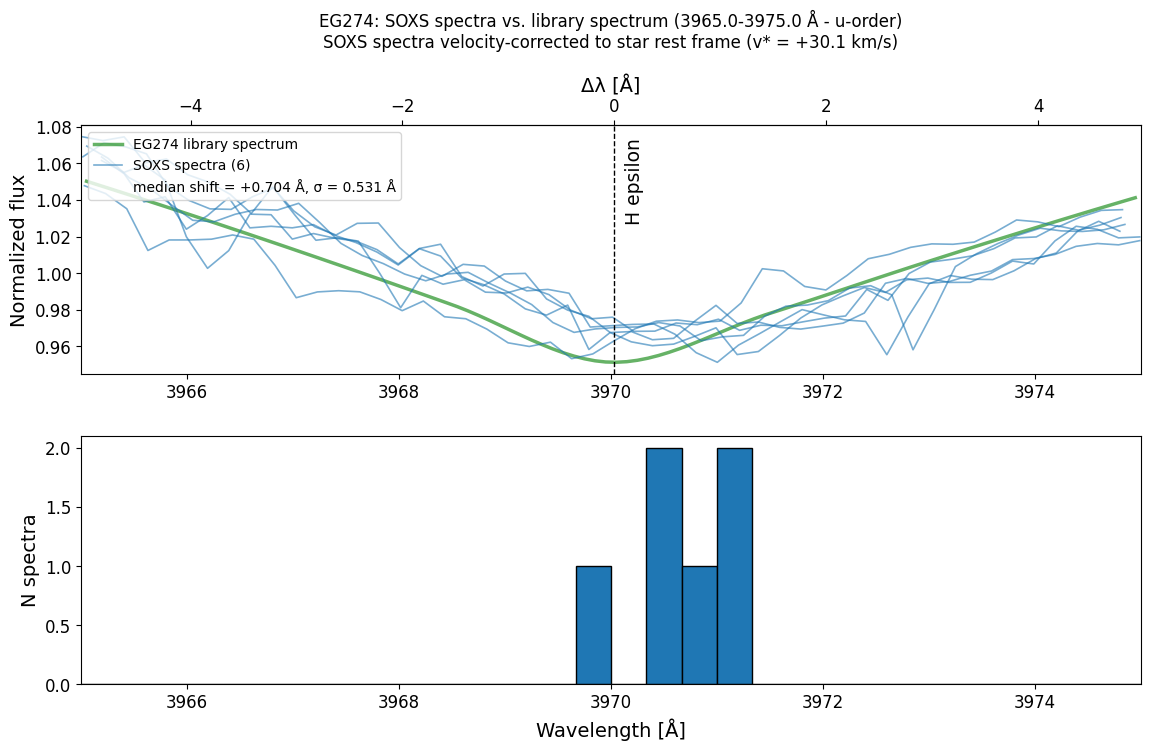

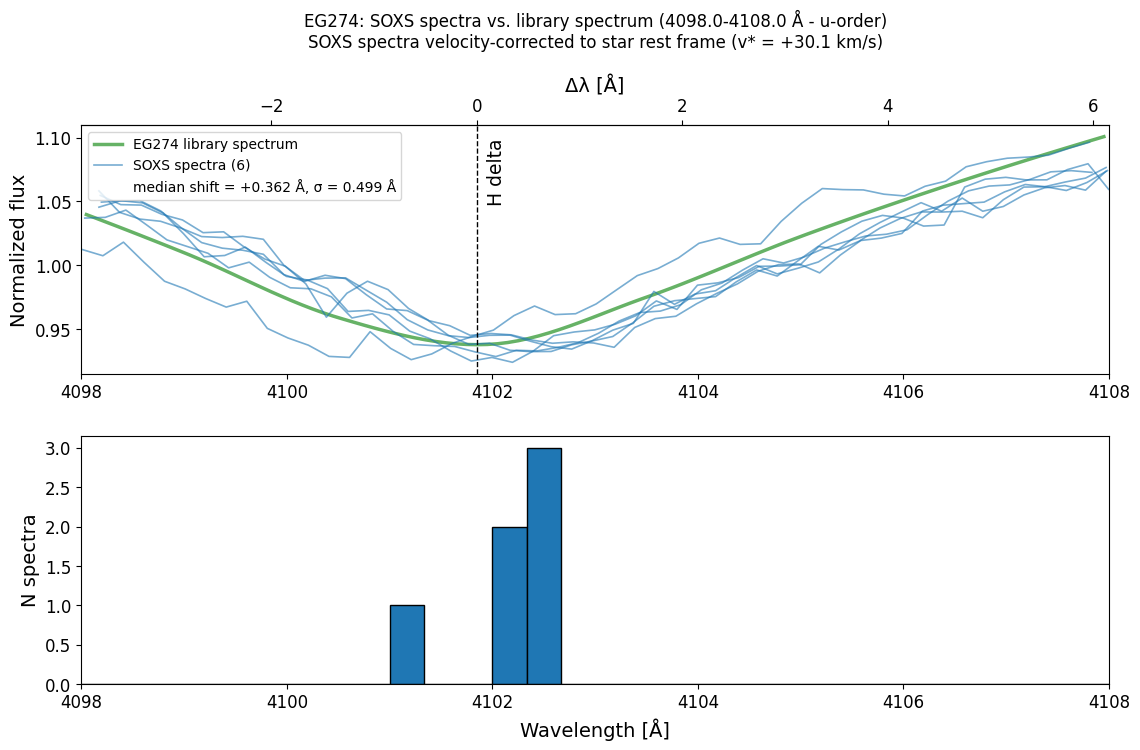

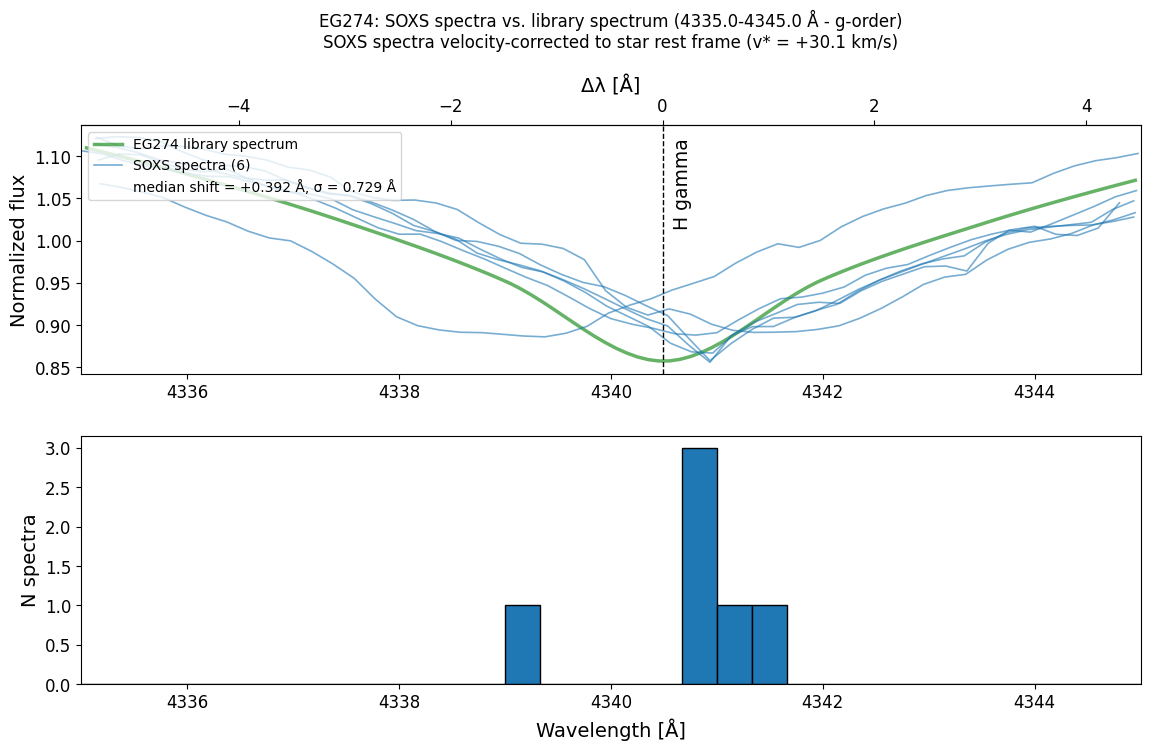

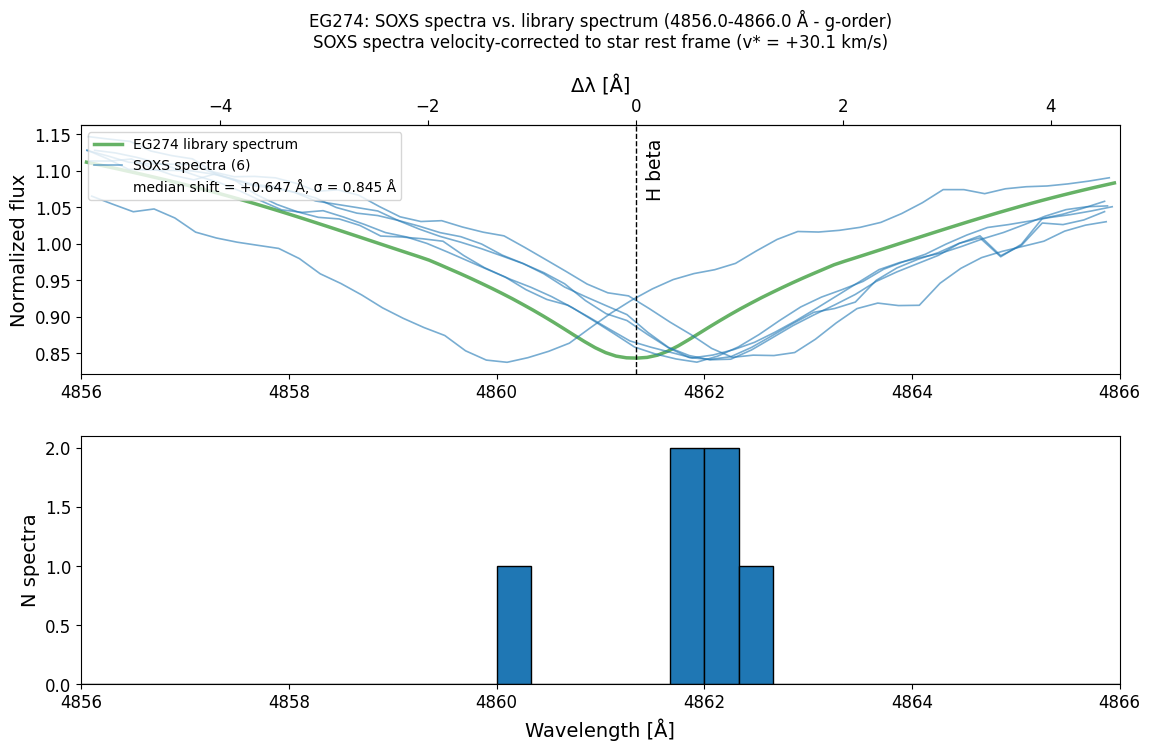

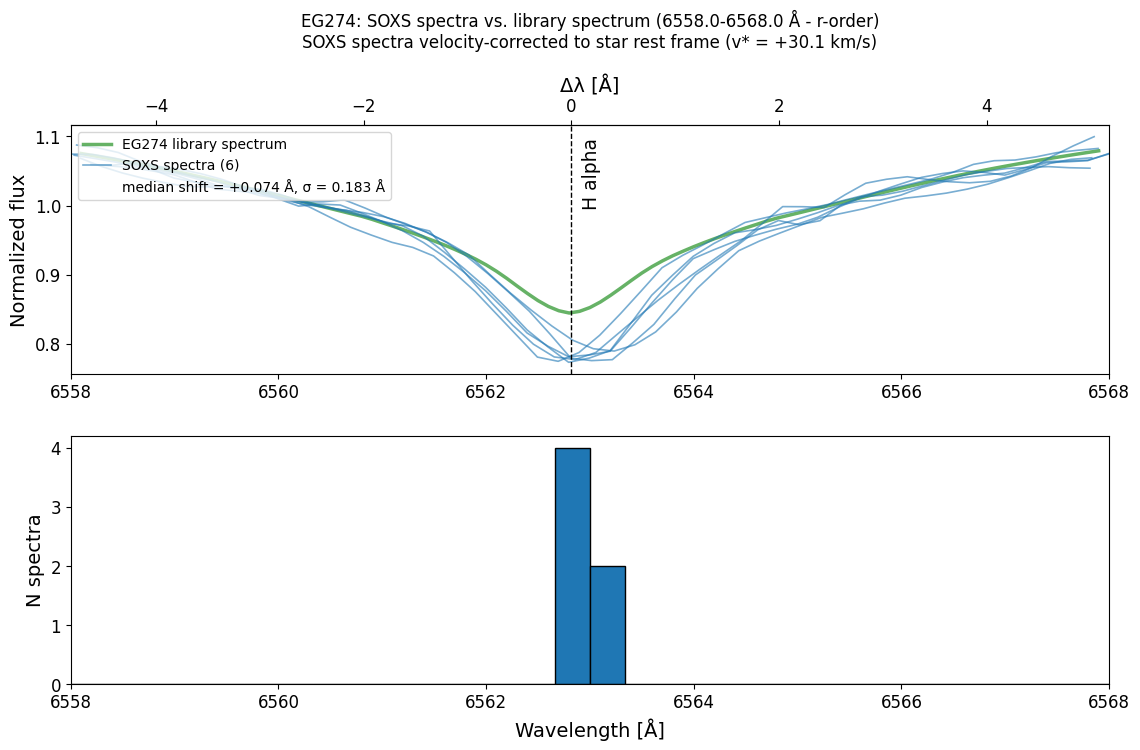

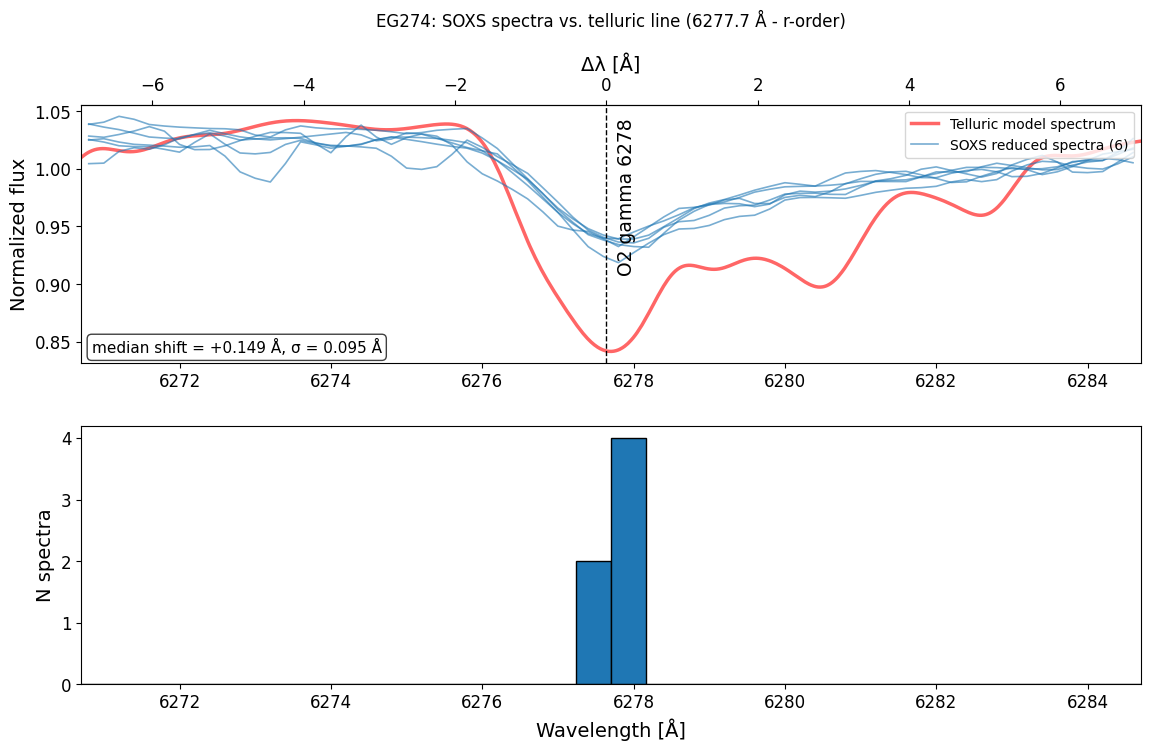

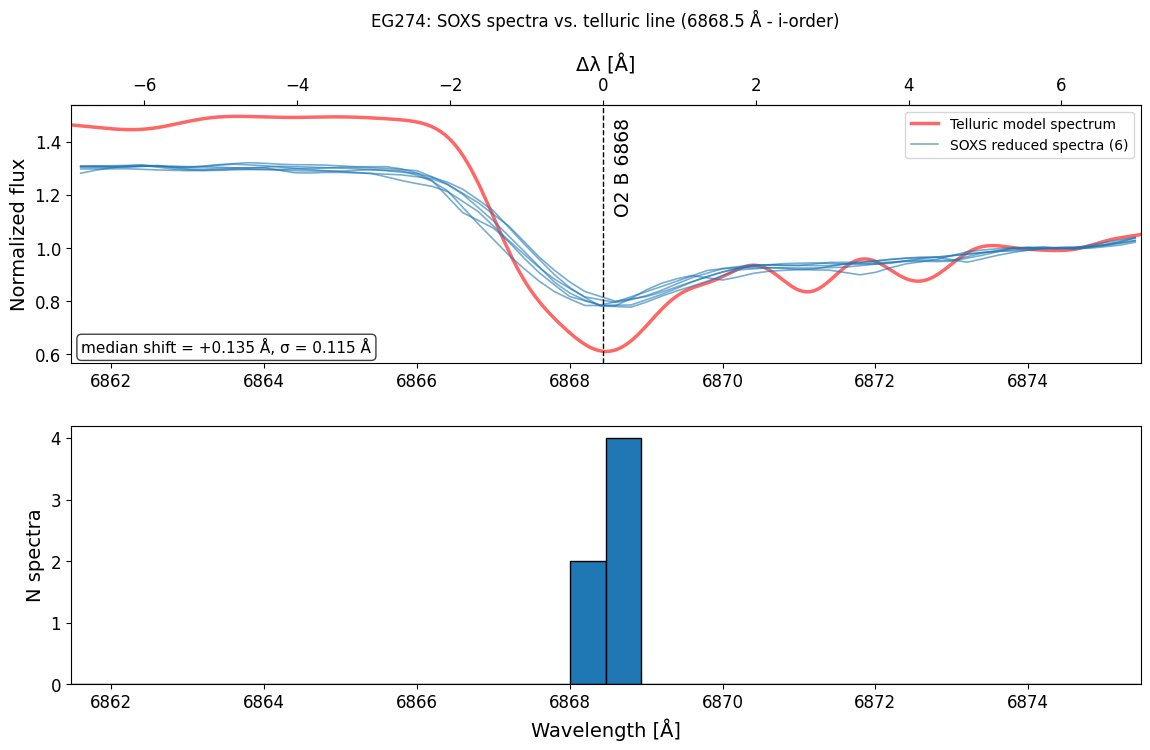

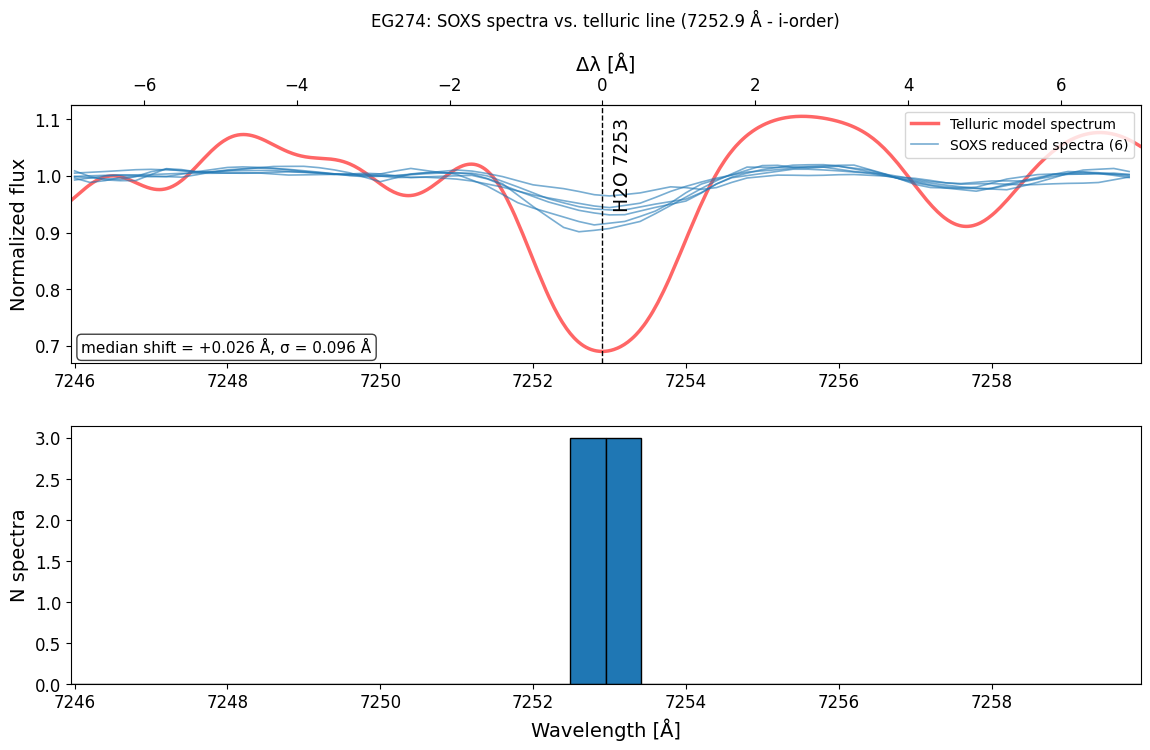

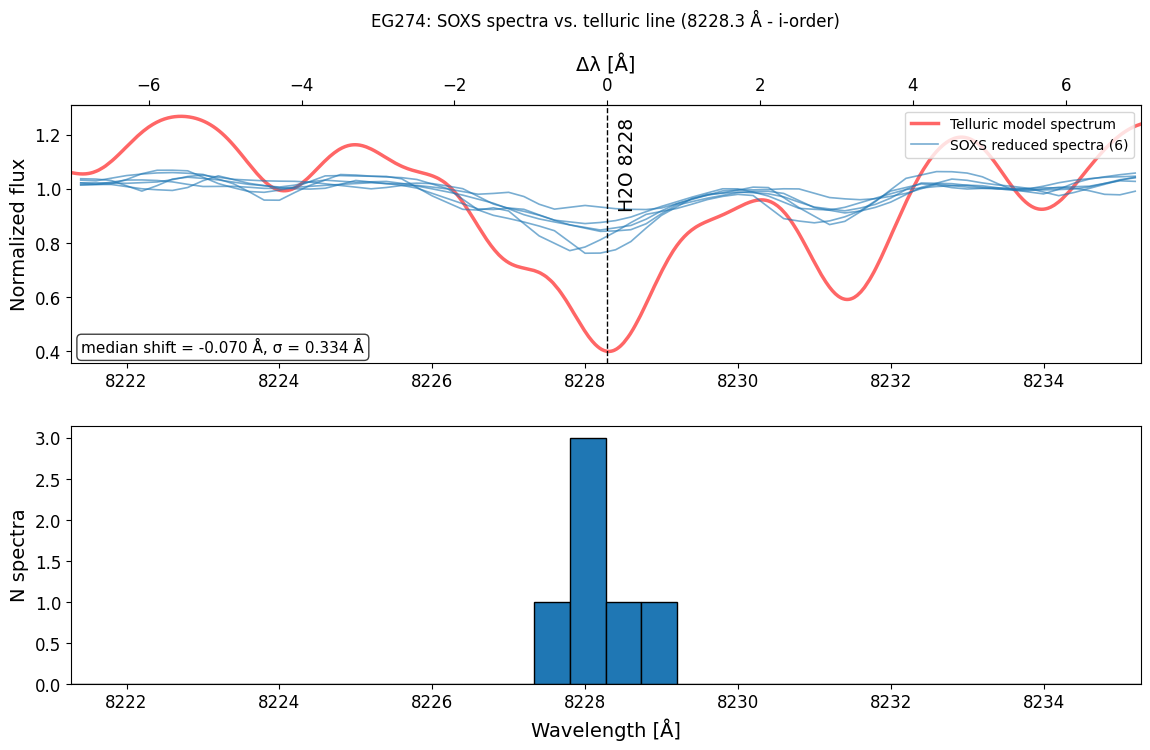

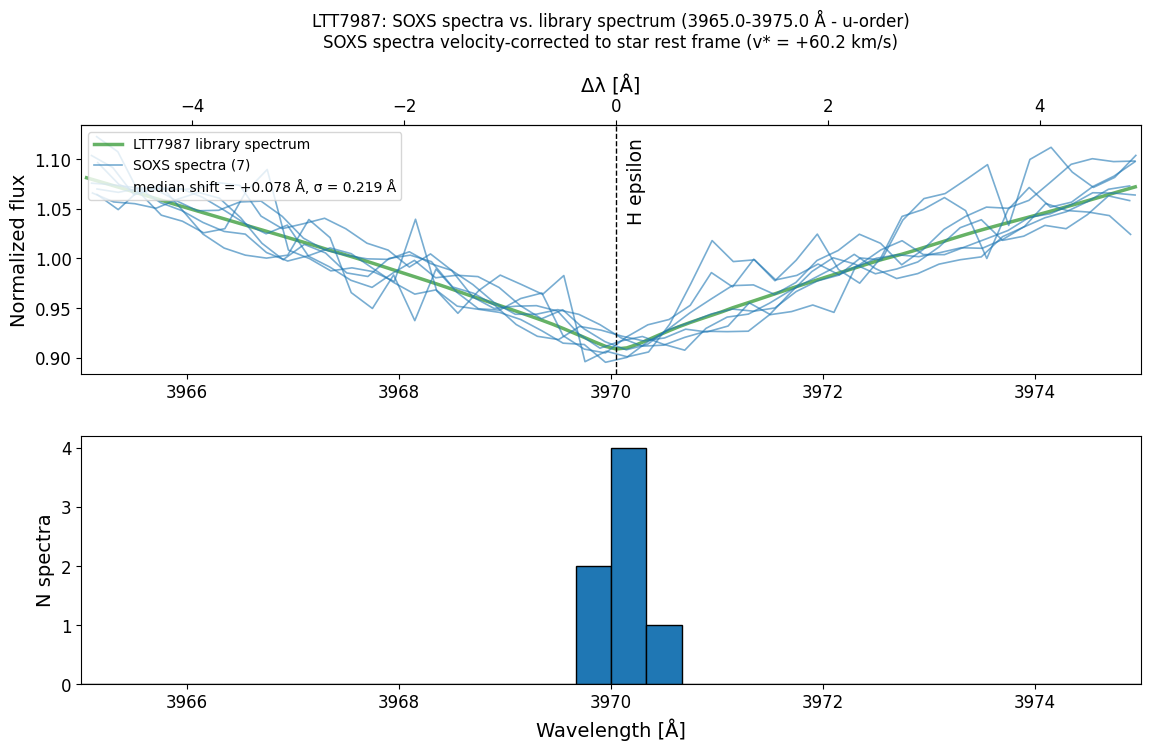

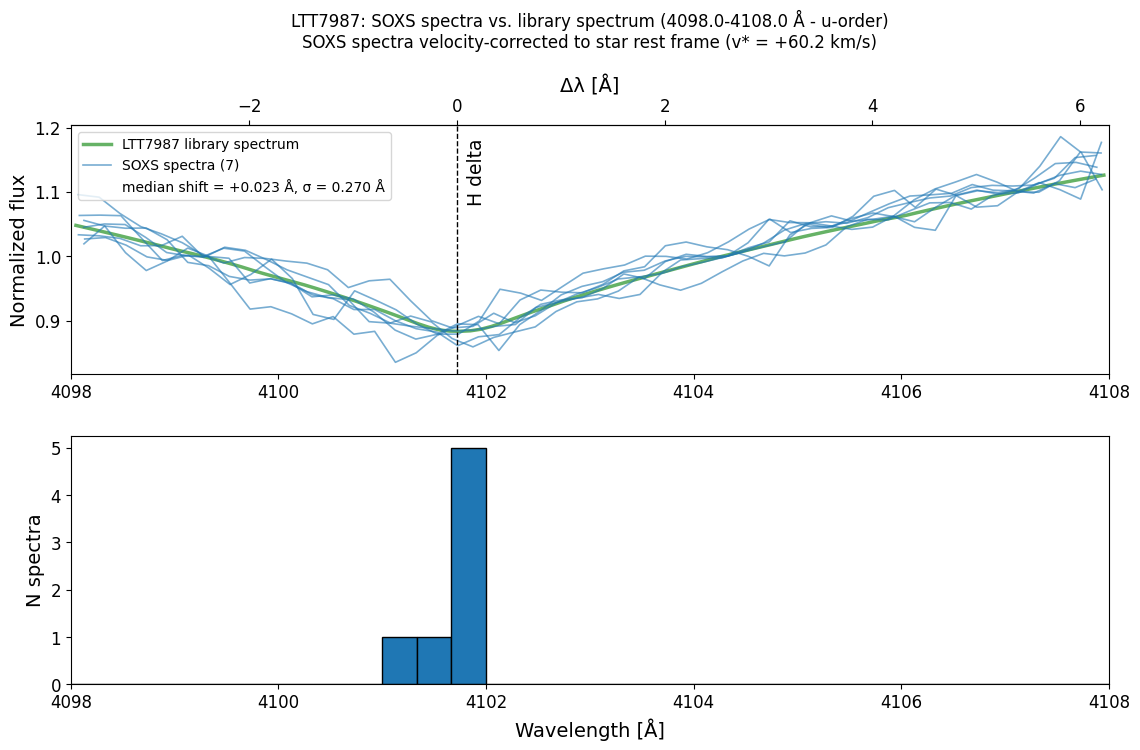

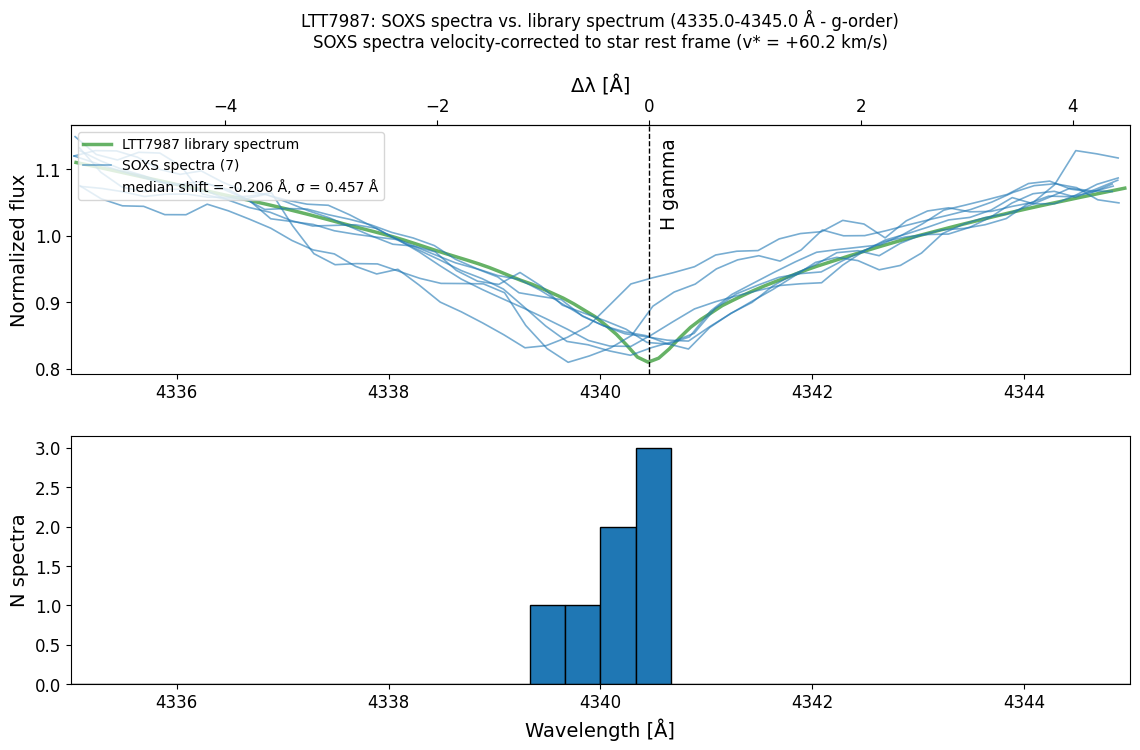

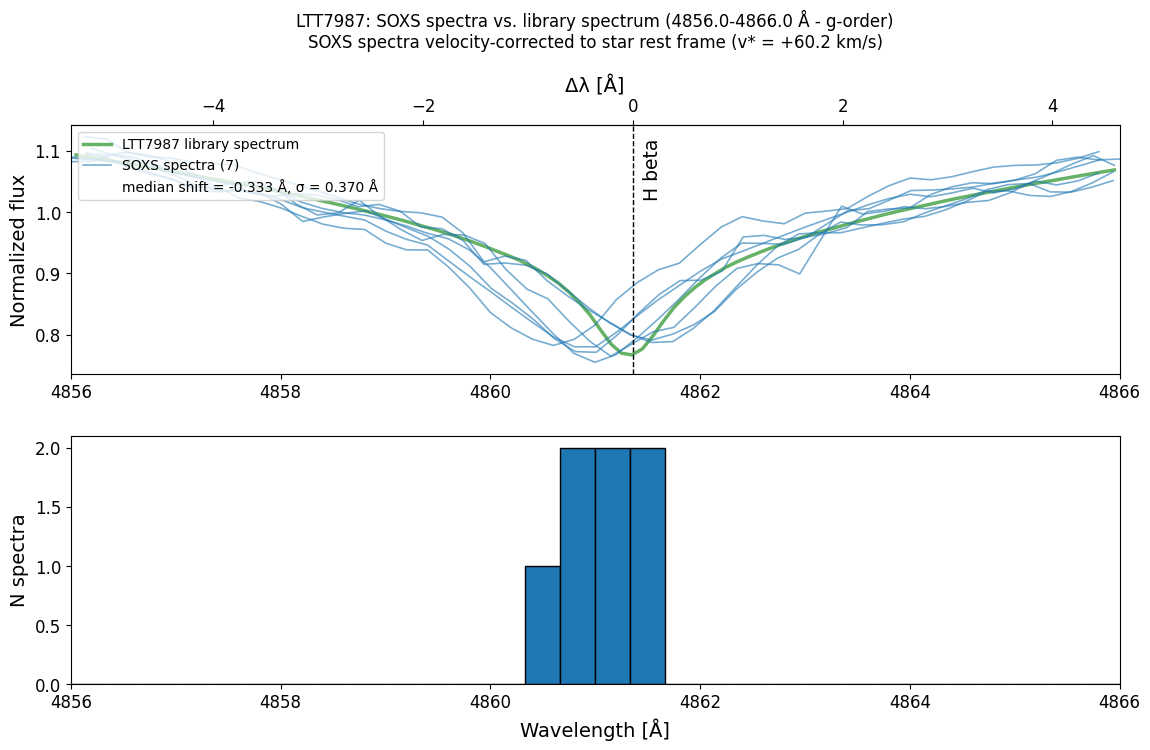

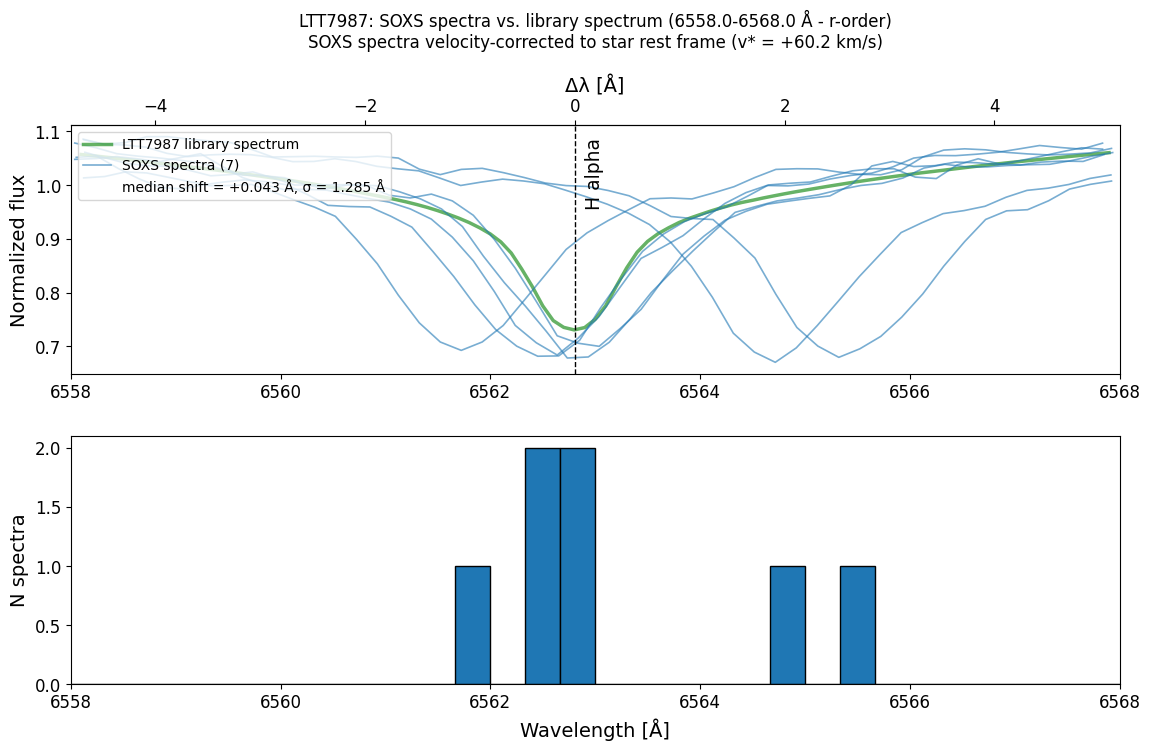

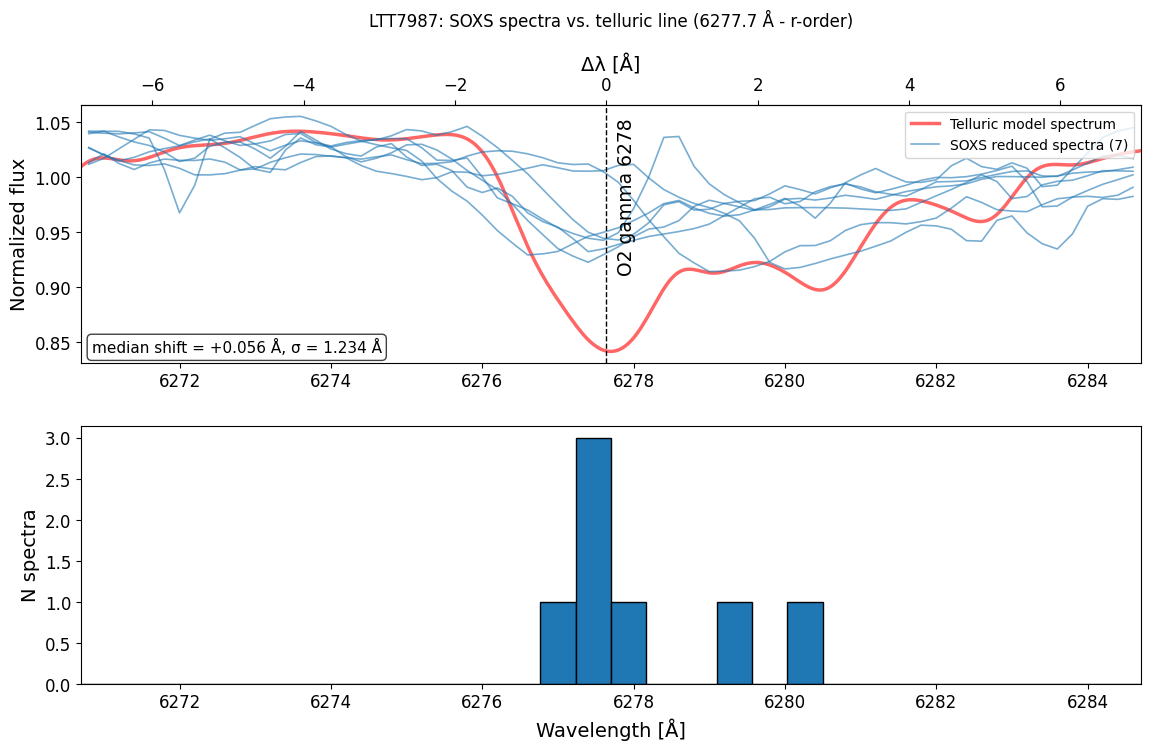

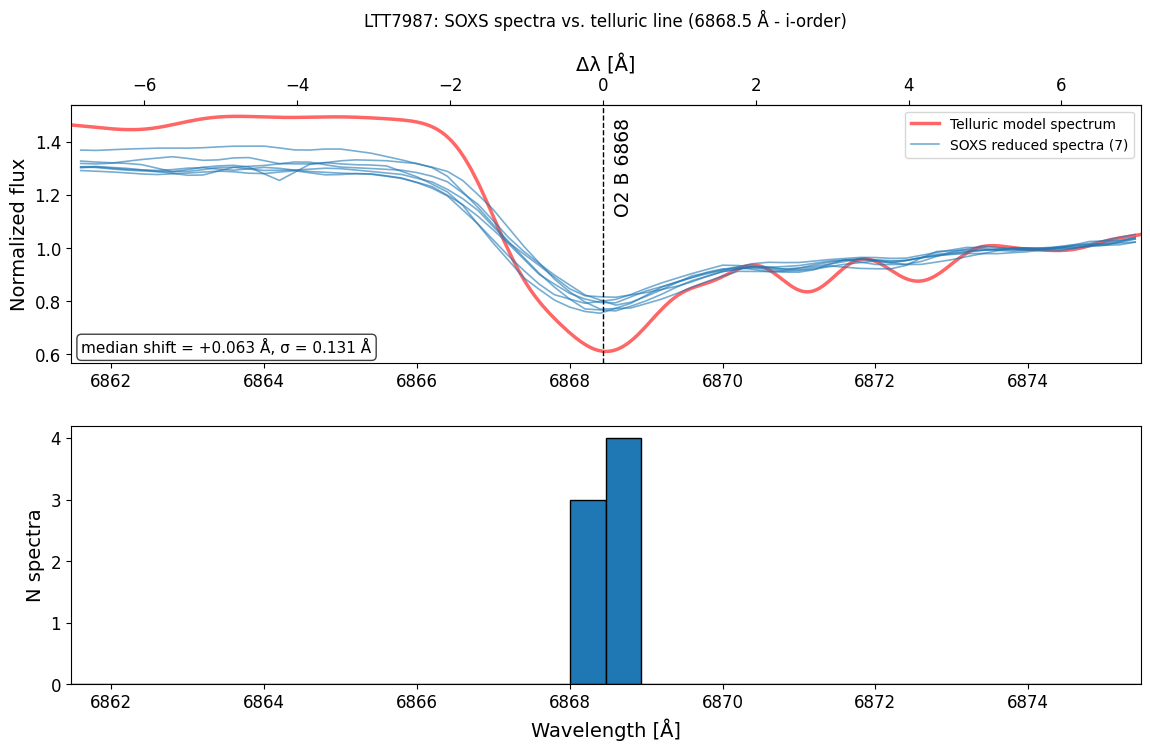

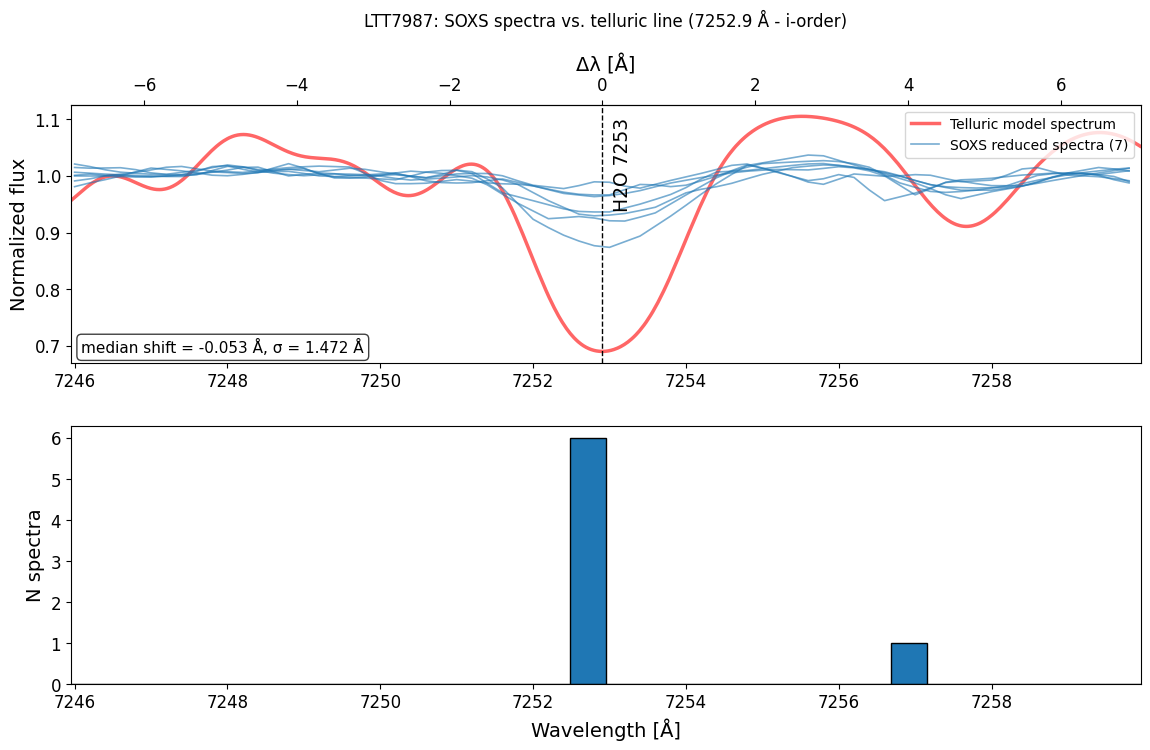

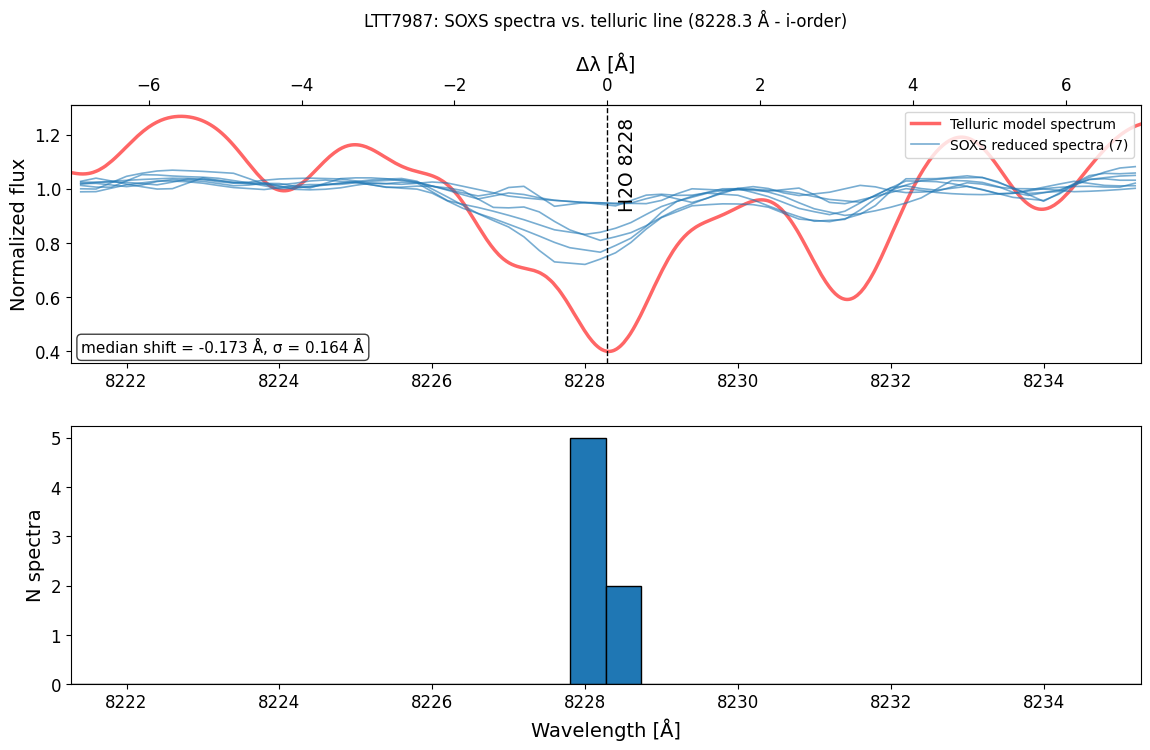

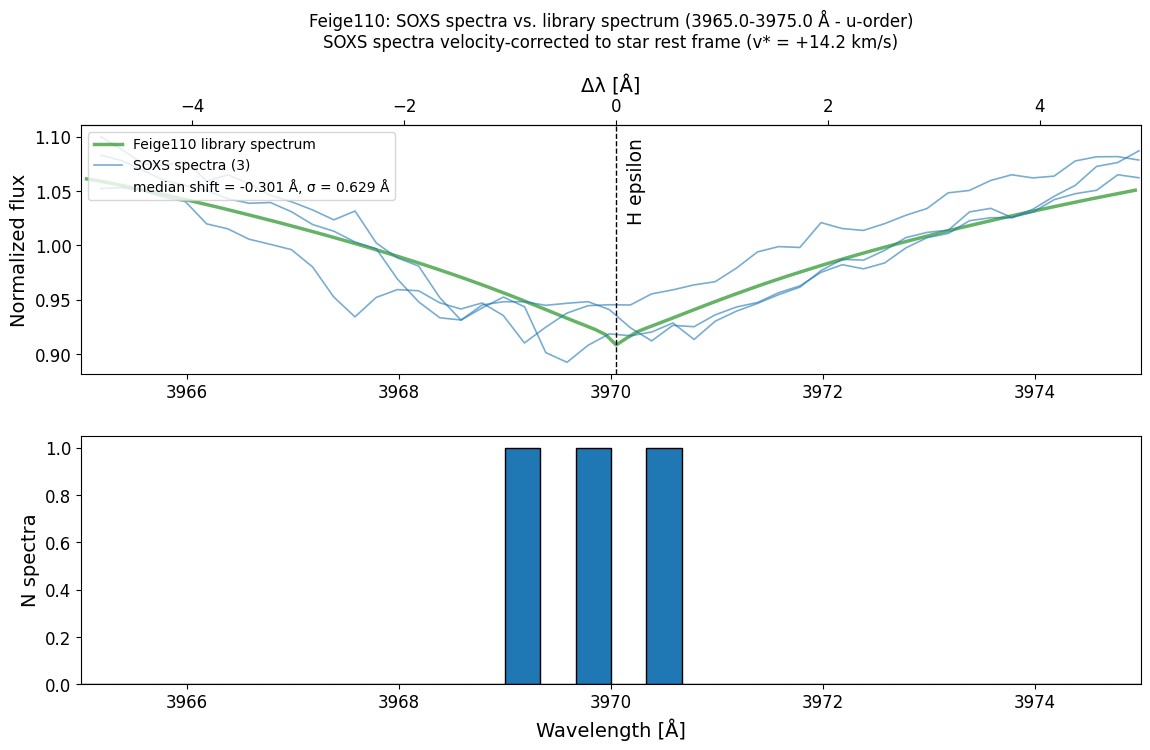

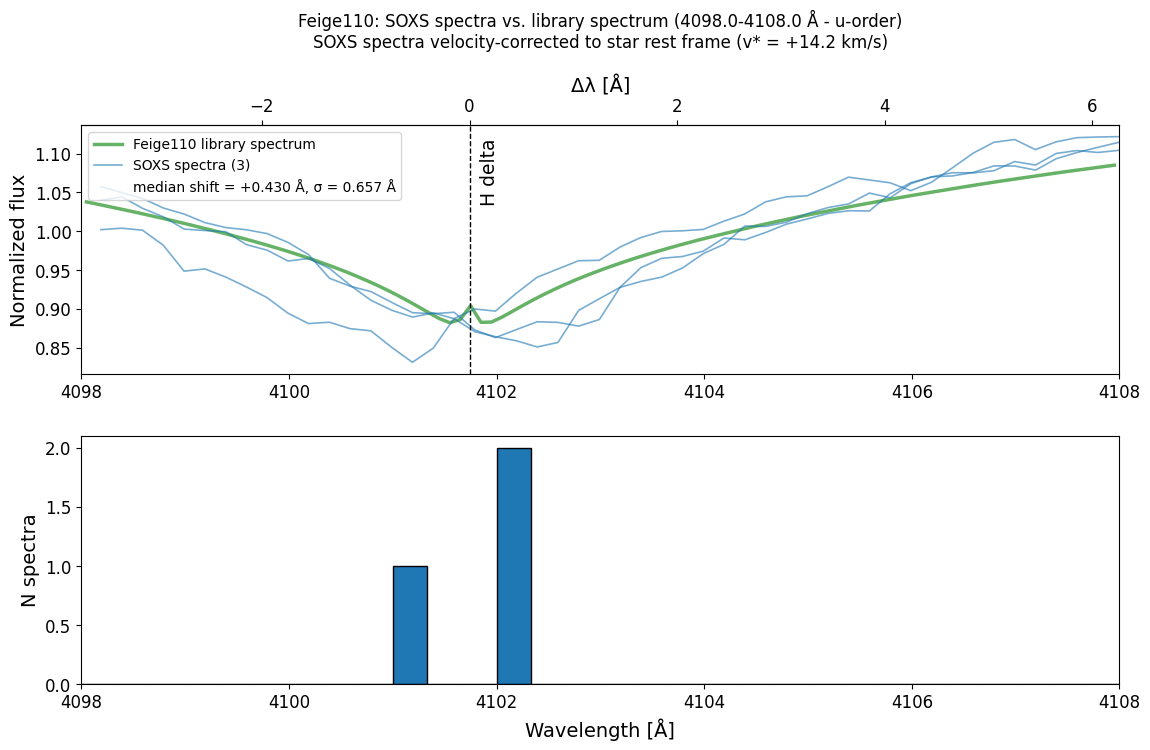

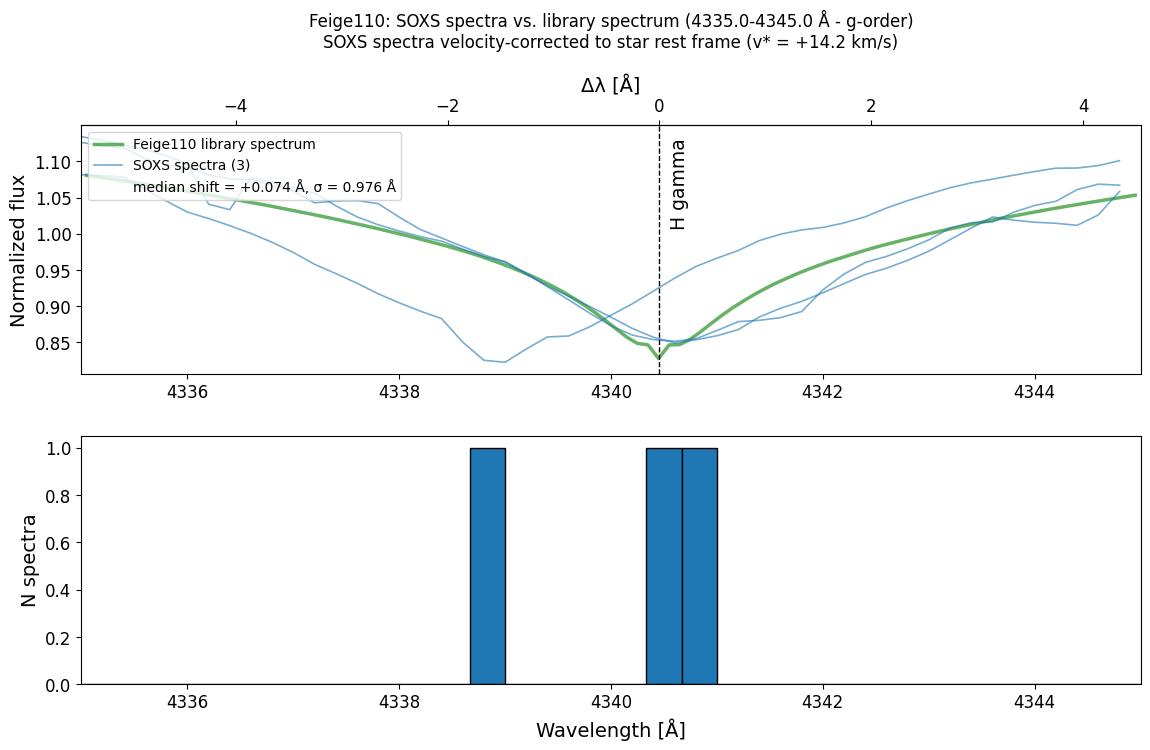

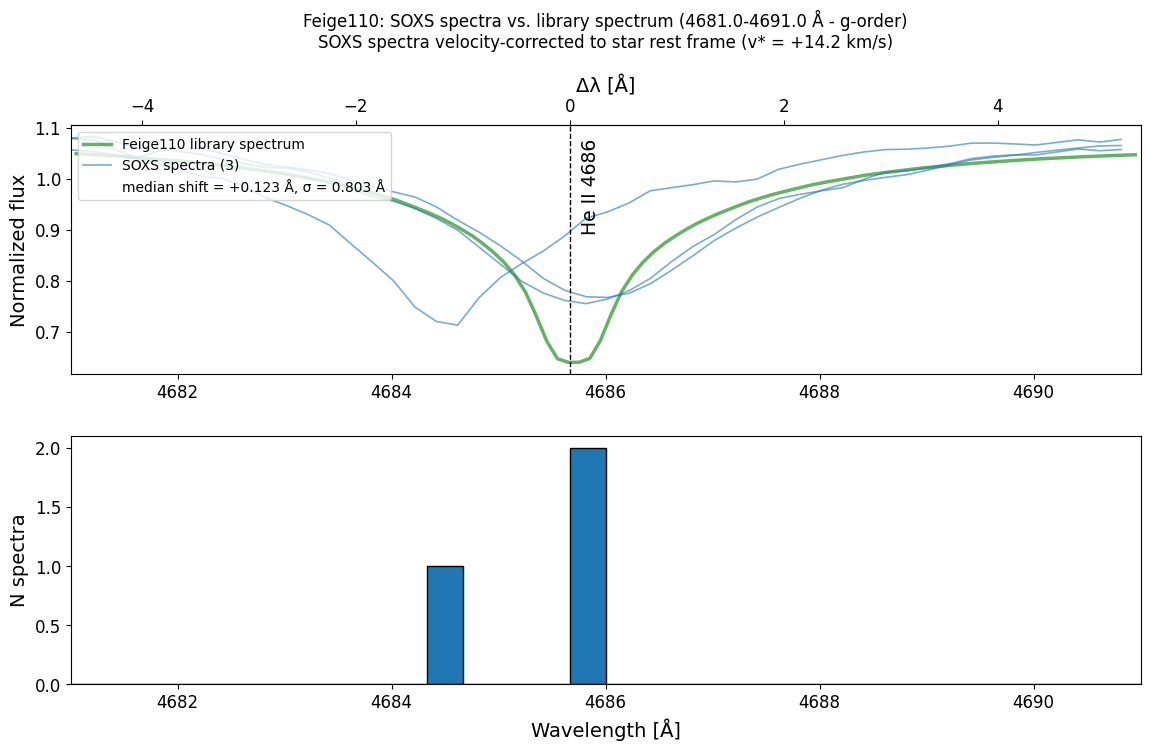

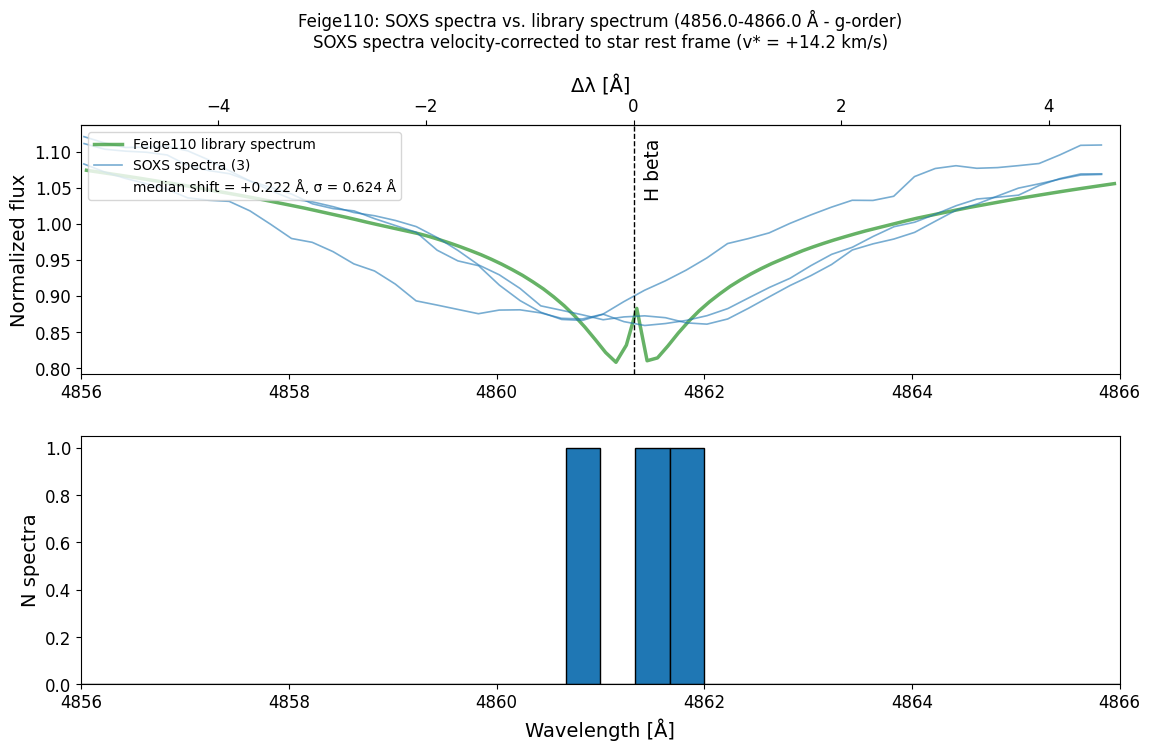

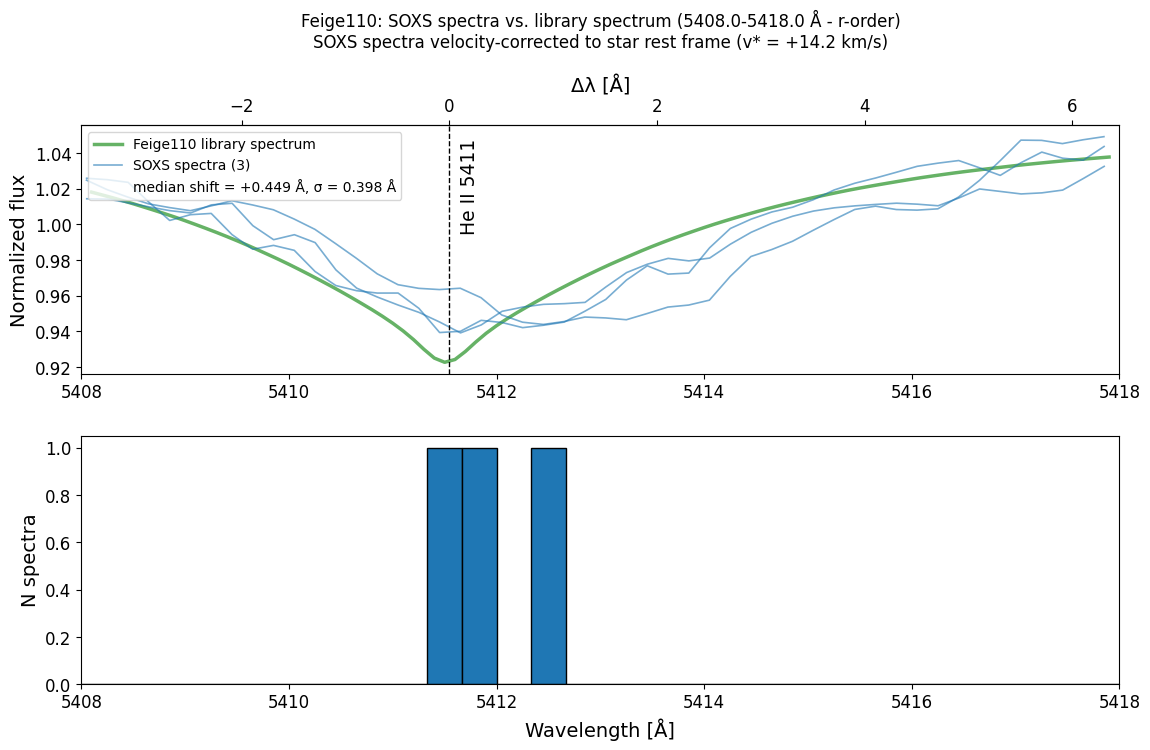

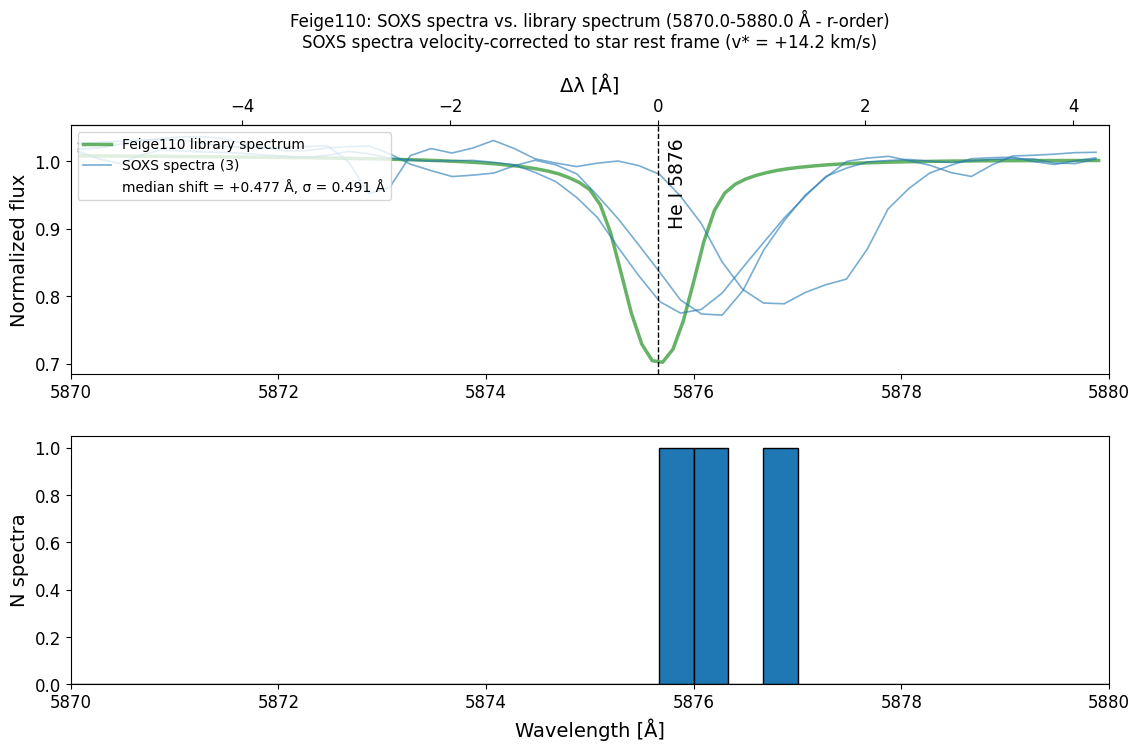

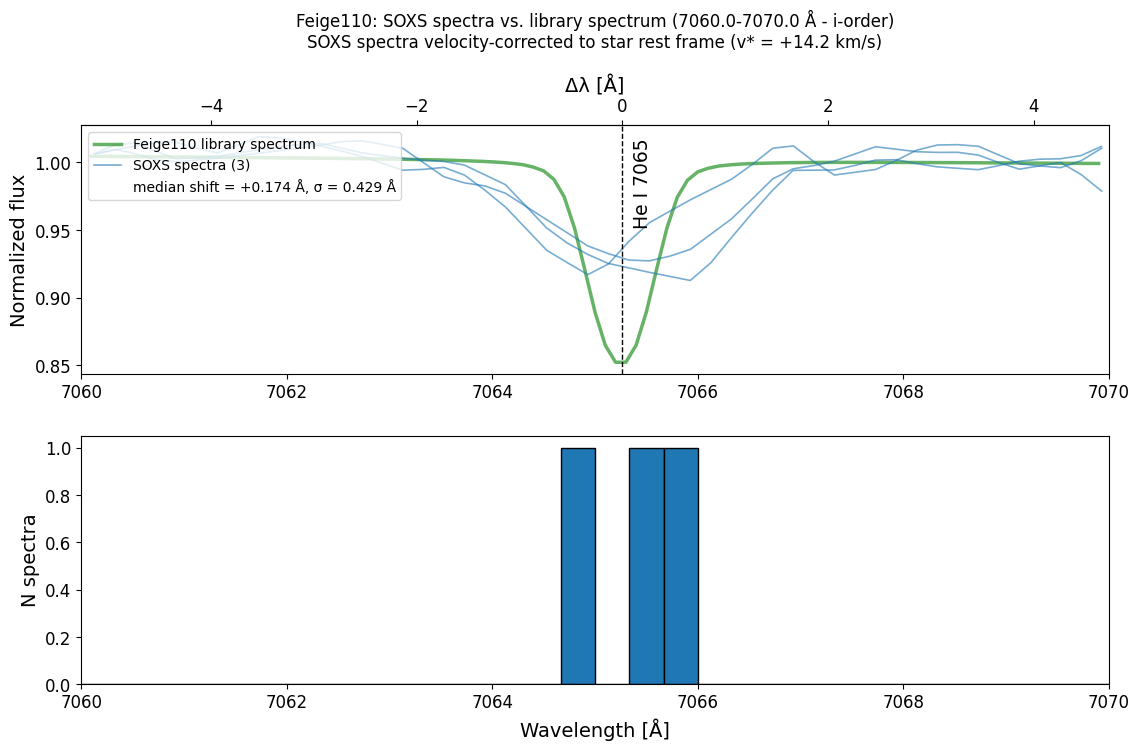

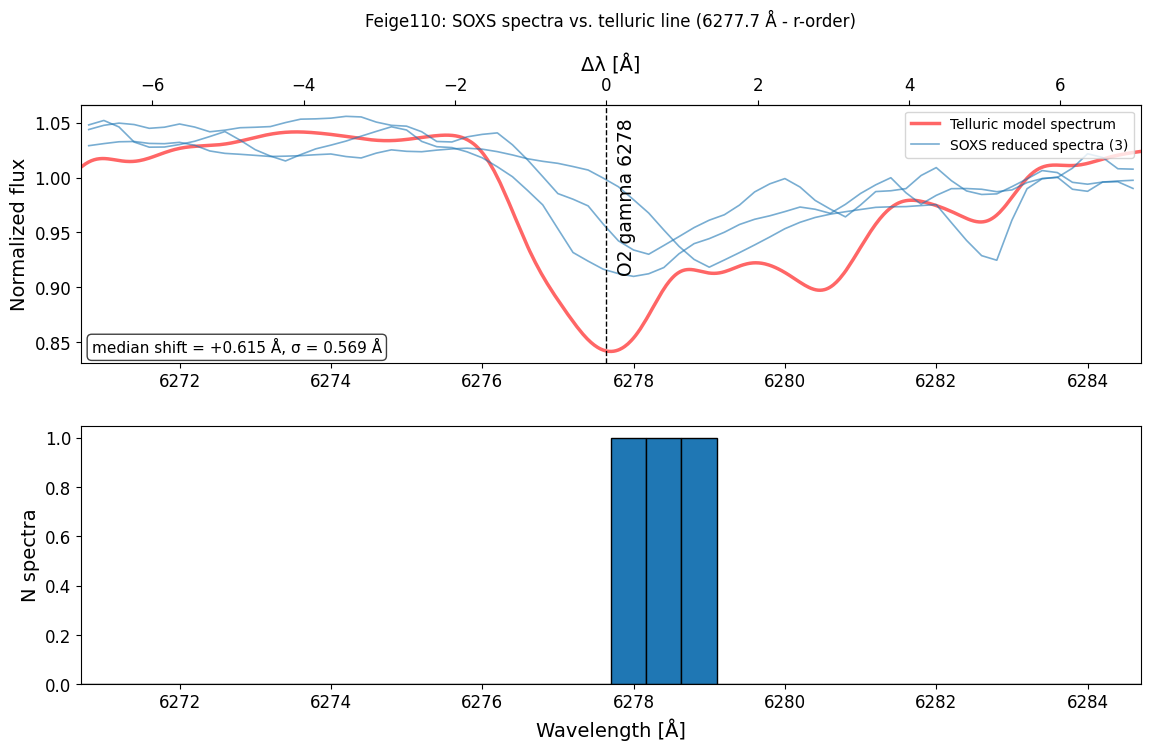

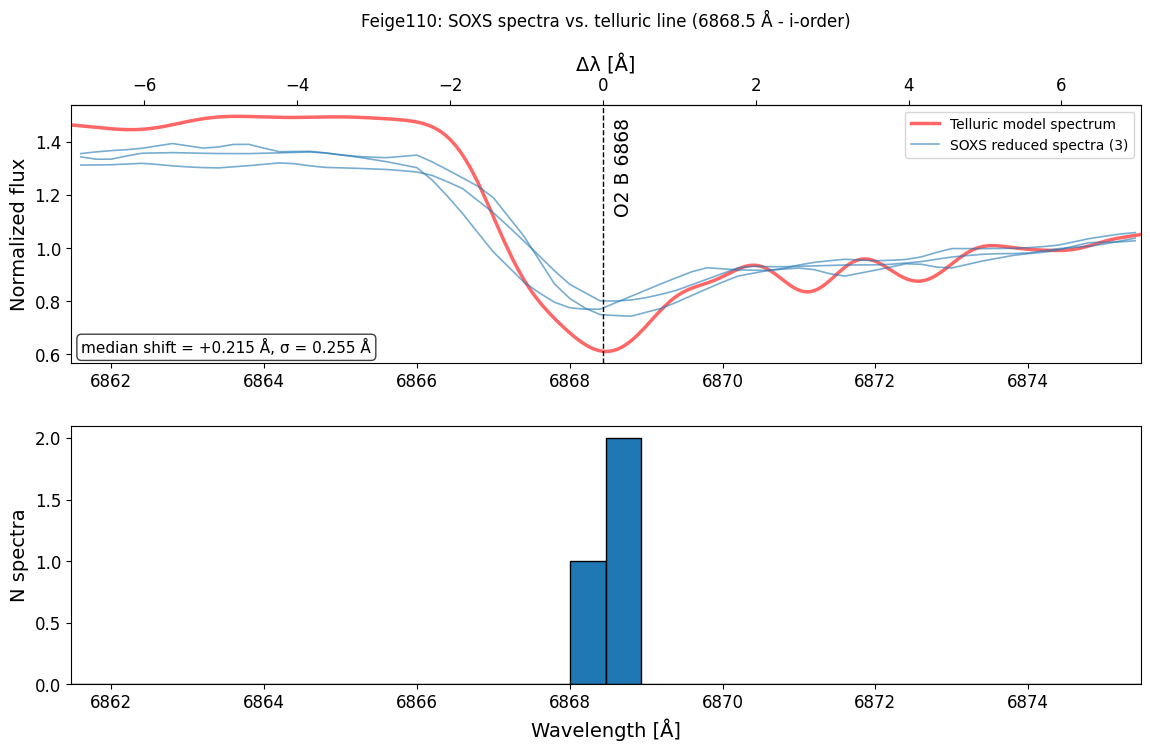

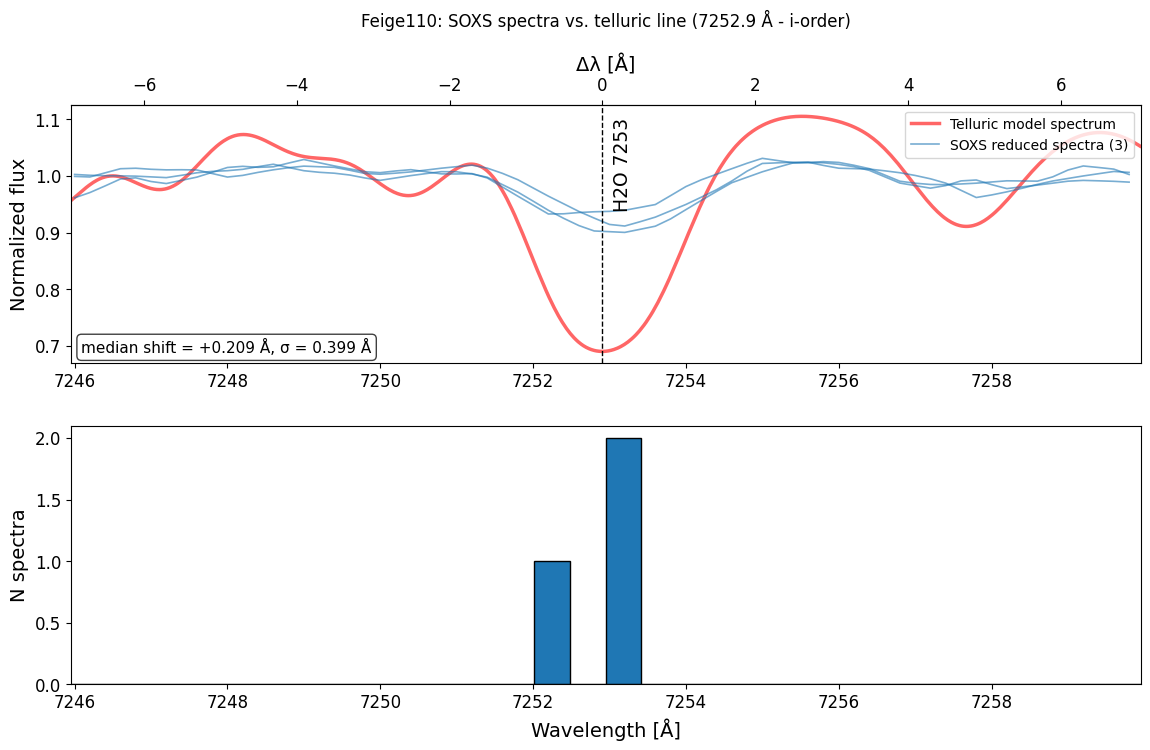

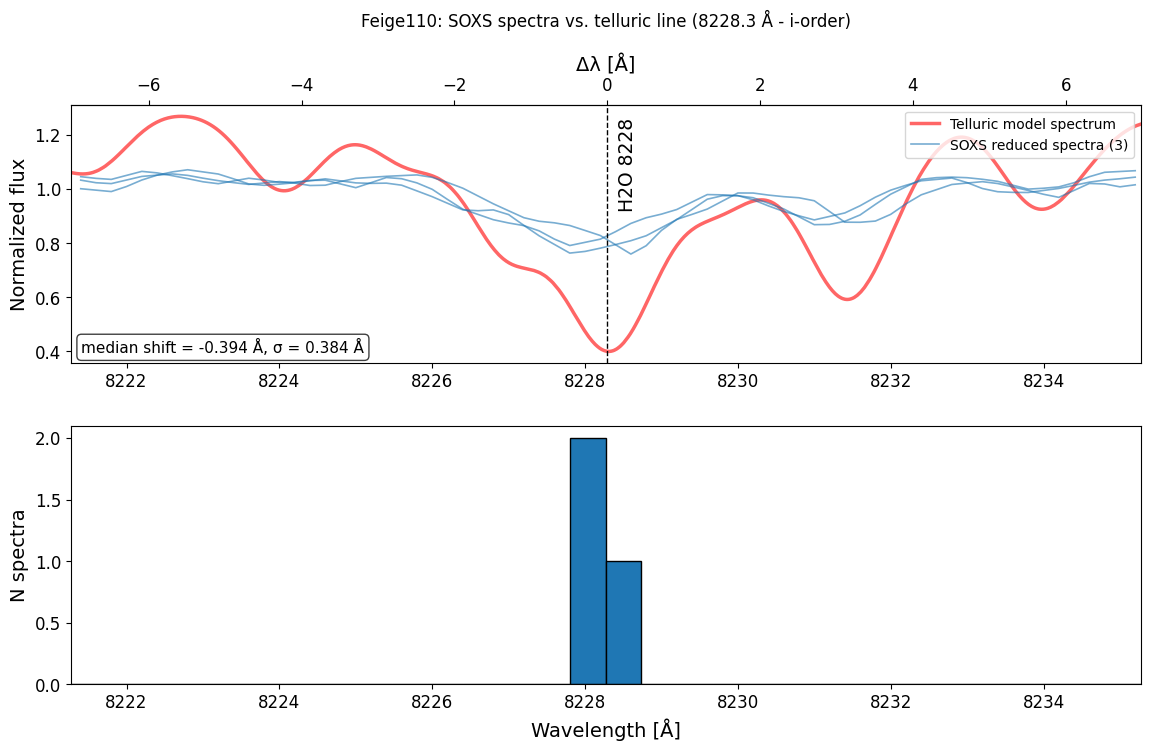

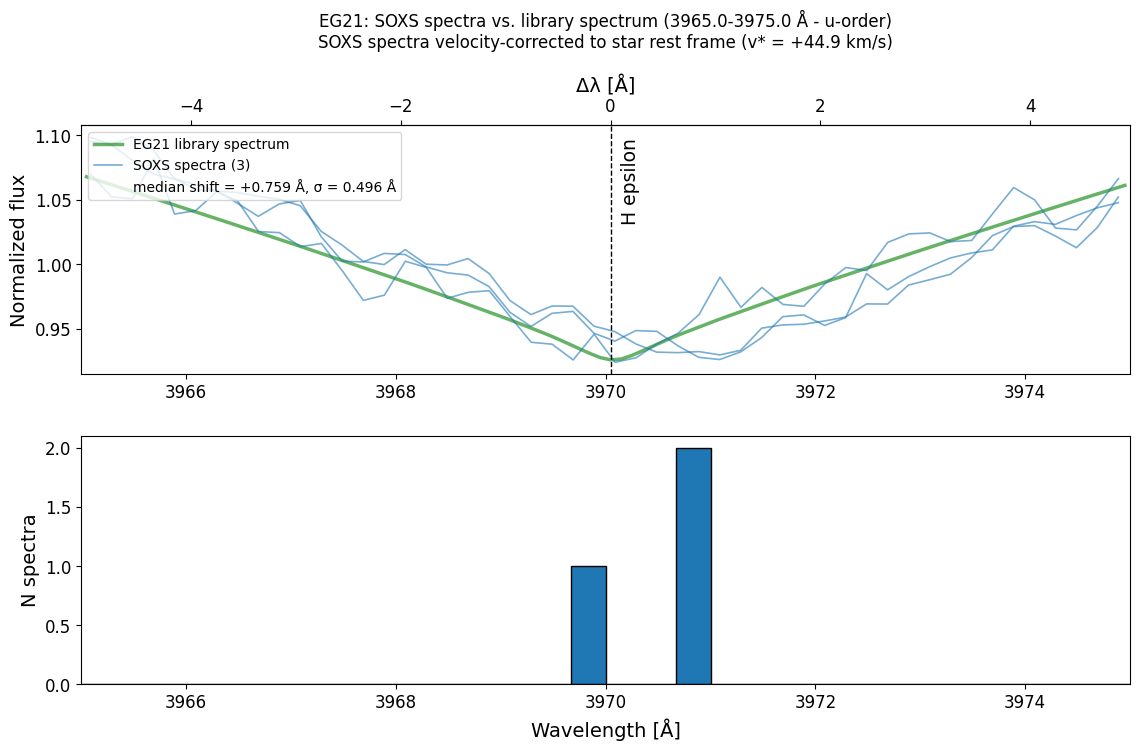

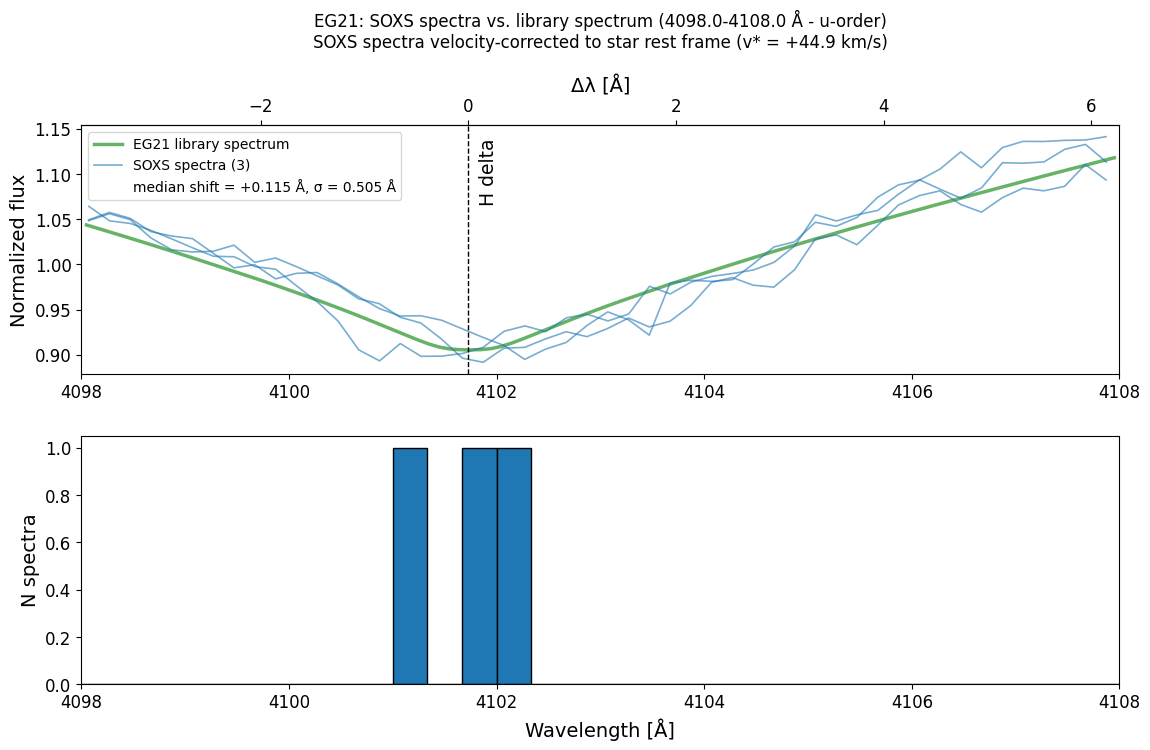

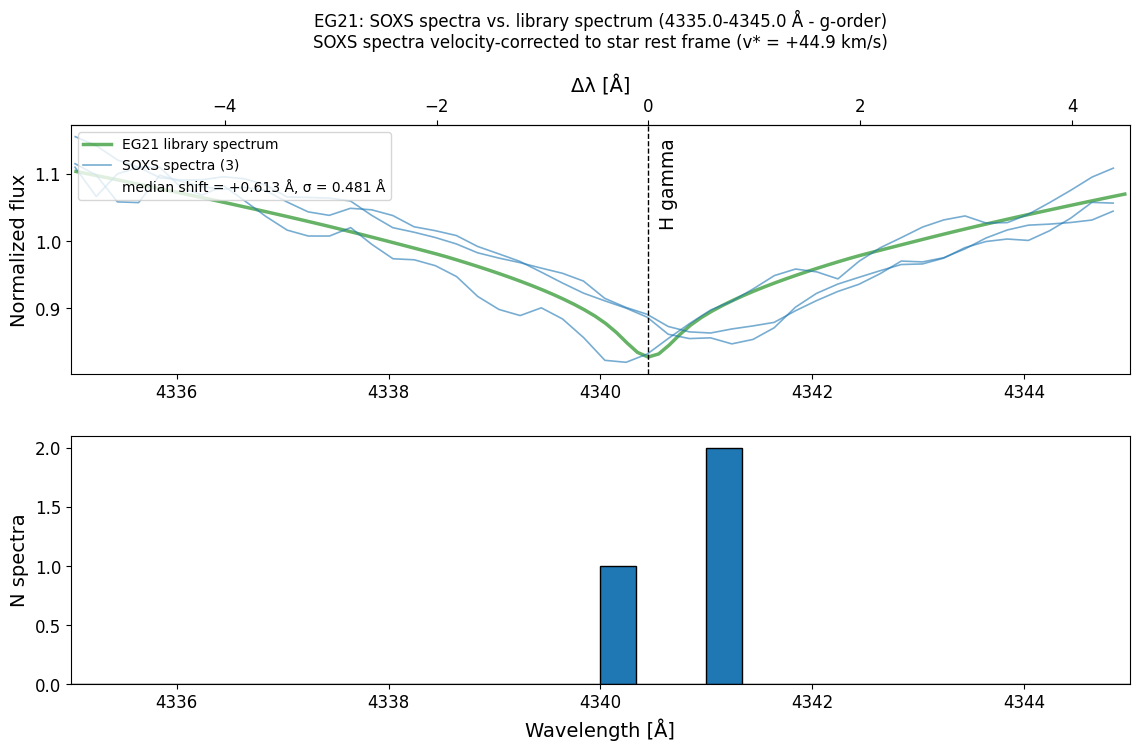

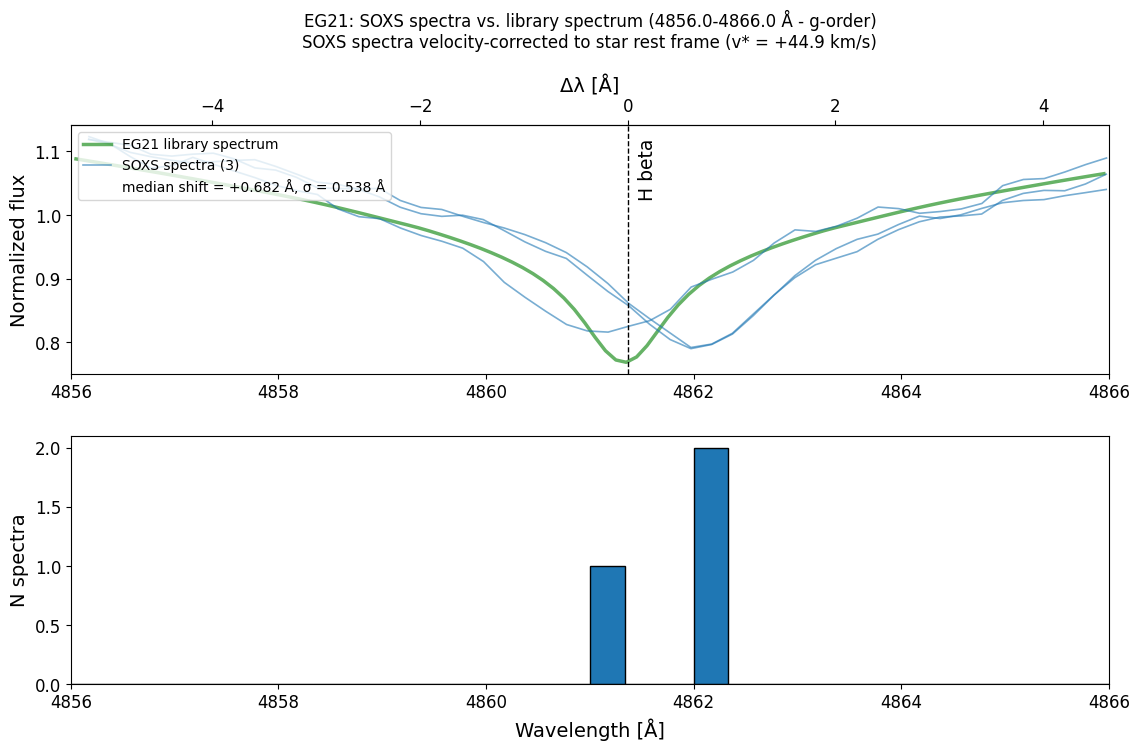

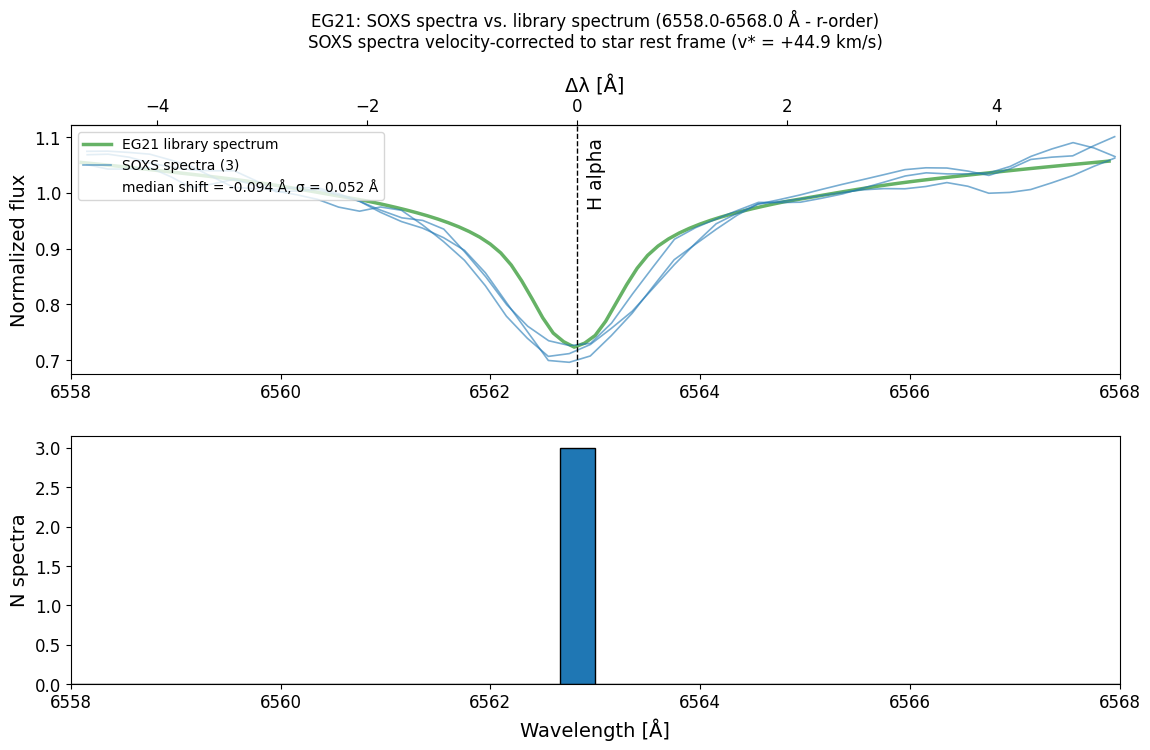

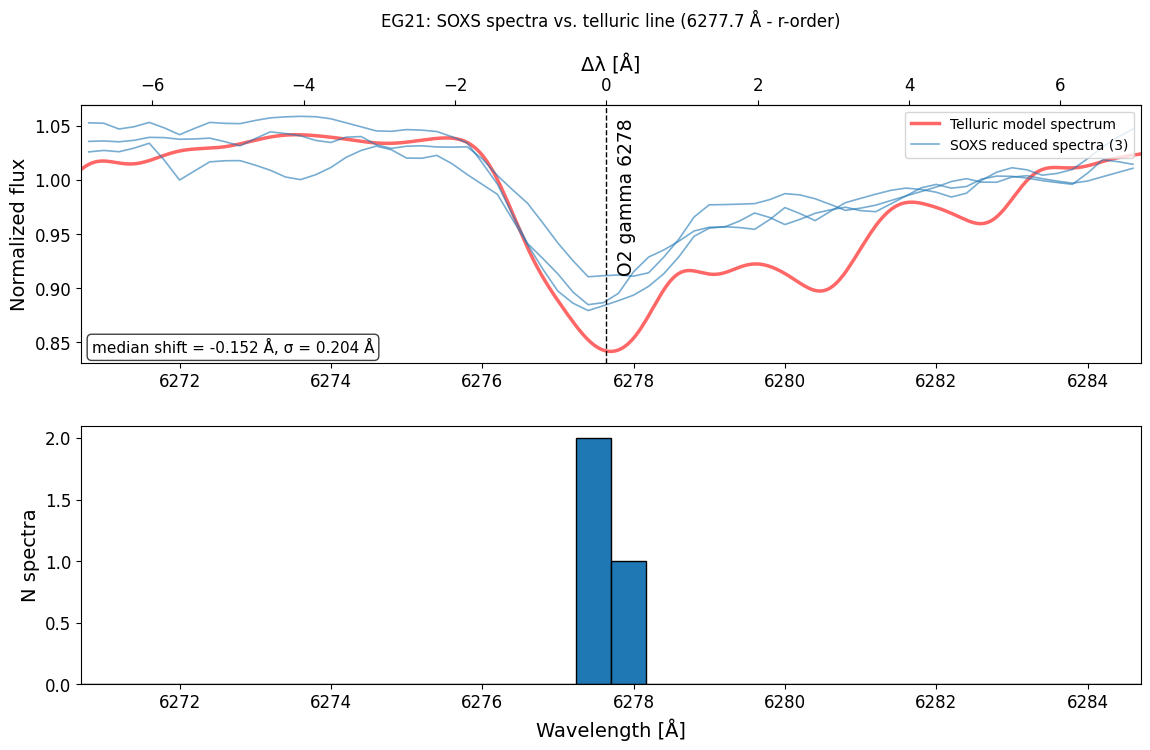

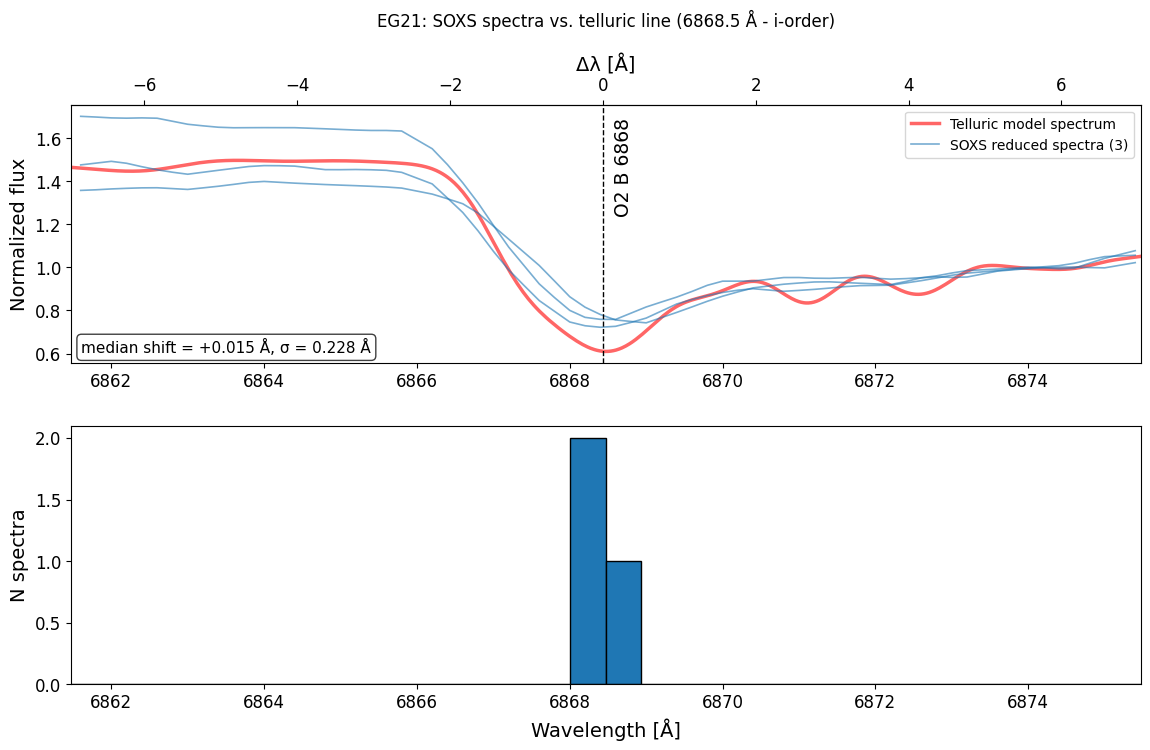

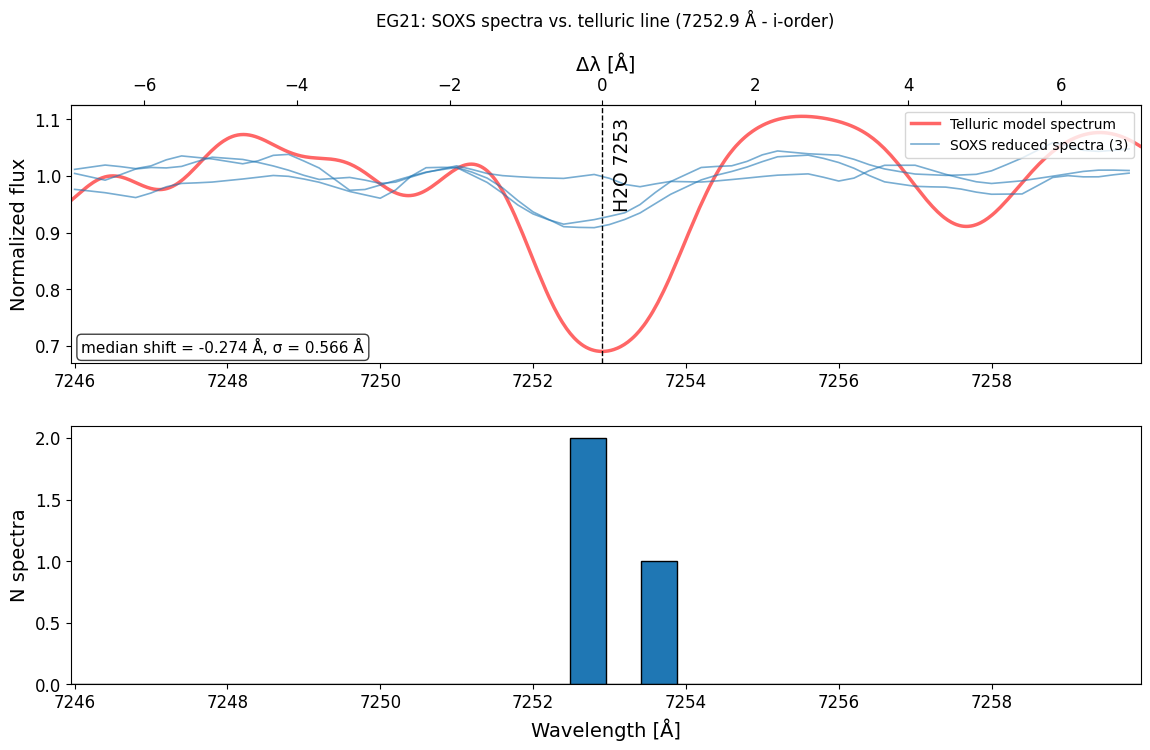

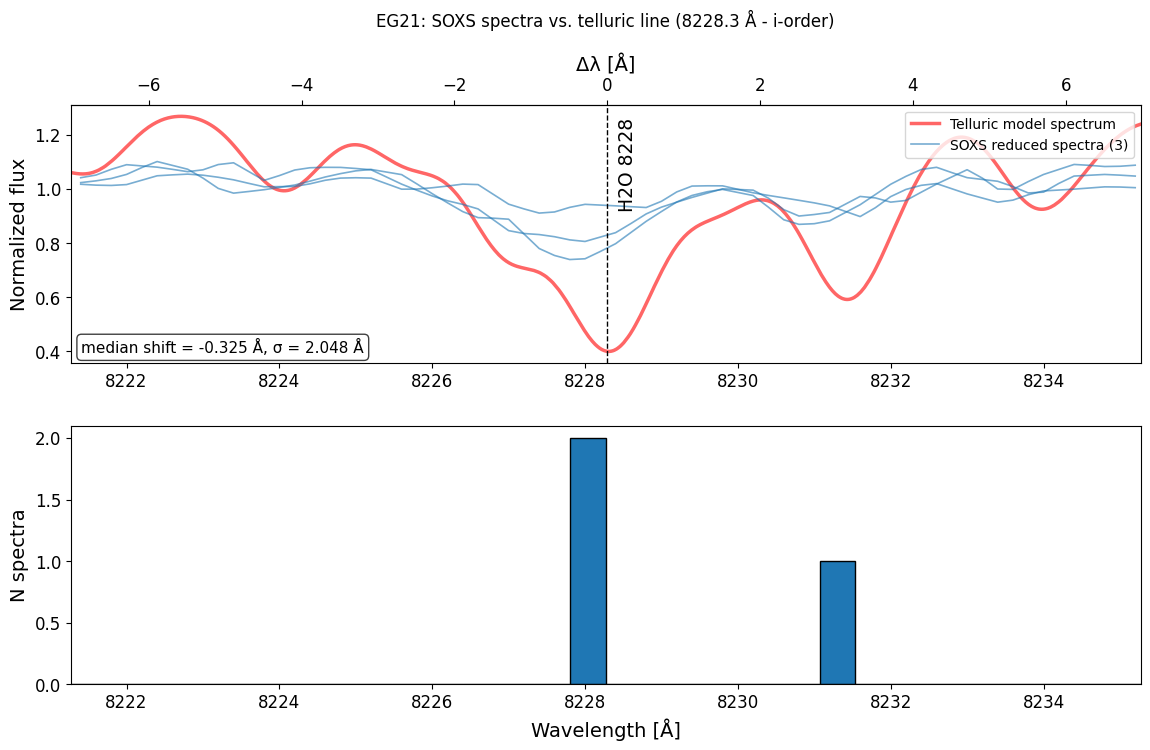

In [20]:
# PLOT: COMPARISON (+ OPTIONAL METRICS) PLOTS FOR EVERY MEASURED (STAR, LINE)
# (REUSES THE MEASUREMENTS FROM resultsDf ABOVE -- NO RE-FITTING)
windowKeys = ['Star', 'LineType', 'Order', 'WindowMinAngstrom', 'WindowMaxAngstrom']
for (starName, lineType, order, windowMin, windowMax), windowRowsDf in resultsDf.groupby(windowKeys, sort=False):
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

    if lineType == 'telluric':
        telluric = (windowMin + windowMax) / 2.0
        windowTag = f"{starName}_telluric_line_{telluric:.0f}A"
        libraryWaveNmArg, libraryFluxArg = telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux
        vStarKms = None
    else:
        telluric = False
        windowTag = f"{starName}_{windowMin:.0f}-{windowMax:.0f}A"
        libraryWaveNmArg, libraryFluxArg = data['WAVE'], data[starName]
        fittedVelocity = starVelocitiesDf.loc[starVelocitiesDf['Star'] == starName, 'VStarKms']
        vStarKms = fittedVelocity.iloc[0] if len(fittedVelocity) else None

    resultsForWindow = windowRowsDf.to_dict('records')

    plot_comparison(
        starName, windowMin, windowMax,
        matchedSpectra, matchedDetails,
        libraryWaveNmArg, libraryFluxArg,
        resultsForWindow,
        order,
        telluric=telluric,
        savePath=f"{PLOTS_DIR}{windowTag}_comparison.png",
        vStarKms=vStarKms,
    )
    if PLOT_METRICS:
        plot_metrics(
            starName, windowMin, windowMax, resultsForWindow,
            savePath=f"{PLOTS_DIR}{windowTag}_metrics.png",
        )


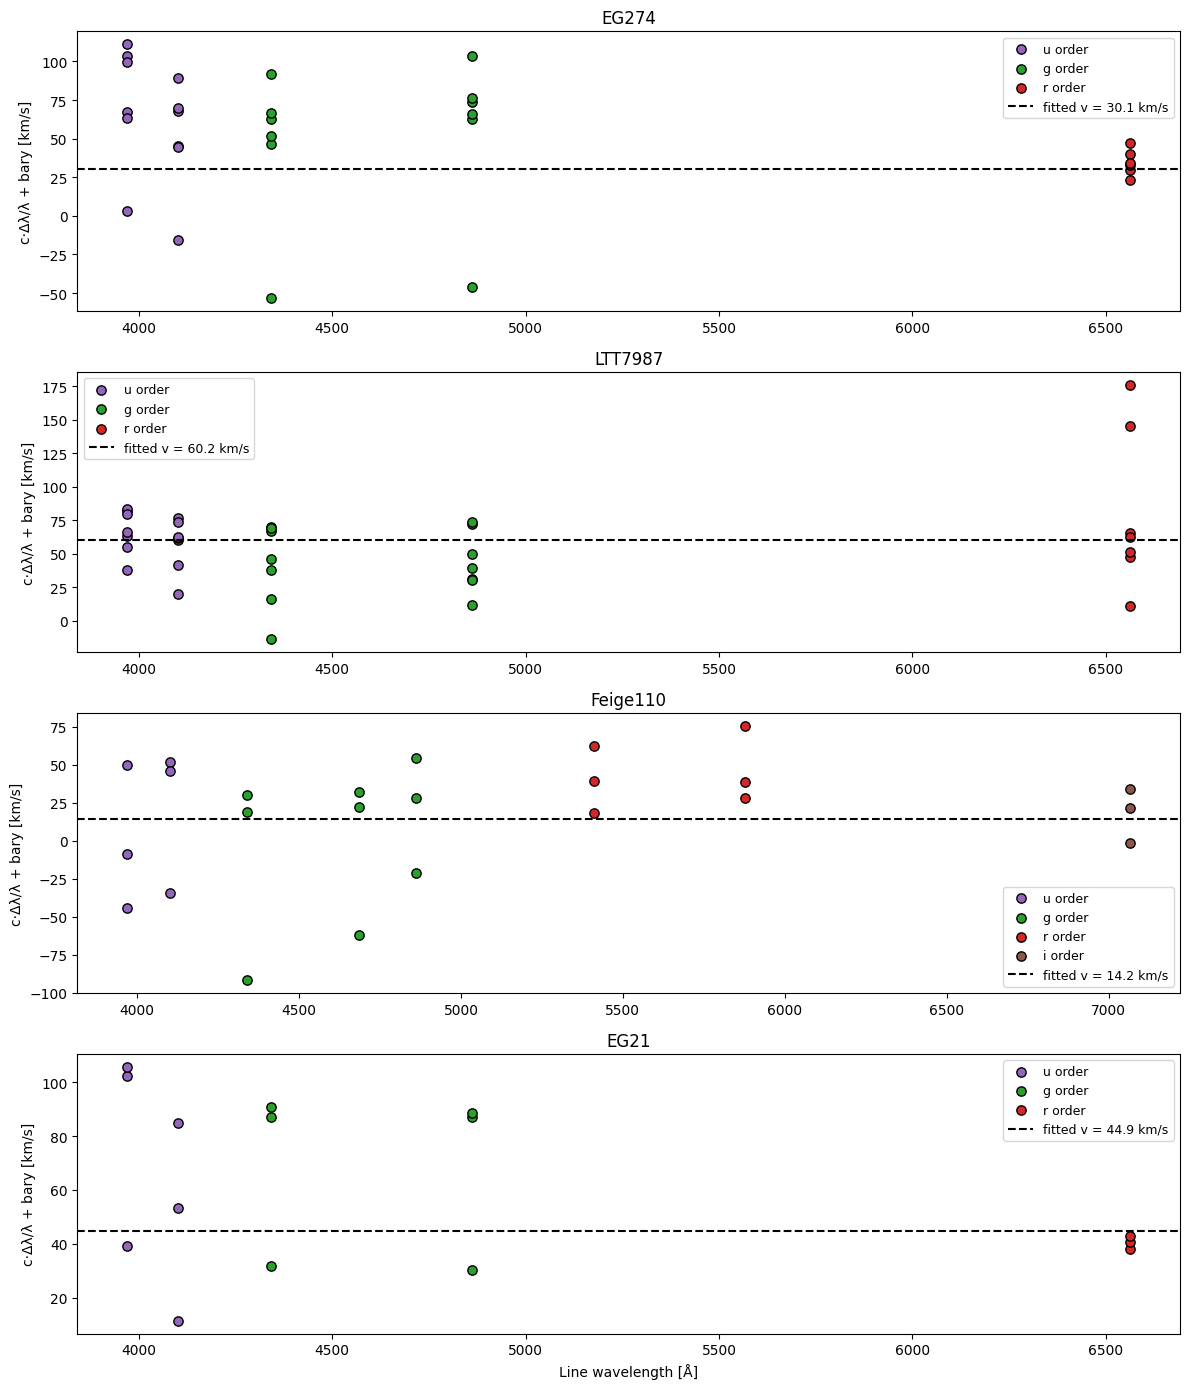

In [21]:
# DIAGNOSTIC PLOT: LINE SHIFT AS A VELOCITY AGAINST WAVELENGTH, ONE PANEL PER STAR.
# A PURE VELOCITY OFFSET IS A FLAT LINE; A WAVELENGTH-SOLUTION ERROR IN ONE ORDER SHOWS AS A STEP.
orderColors = {'u': 'tab:purple', 'g': 'tab:green', 'r': 'tab:red', 'i': 'tab:brown'}
stellarDf = resultsDf[(resultsDf['LineType'] == 'stellar') & np.isfinite(resultsDf['ShiftAngstrom'])]
velocityStars = list(stellarDf['Star'].unique())

if velocityStars:
    fig, axes = plt.subplots(len(velocityStars), 1, figsize=(12, 3.5 * len(velocityStars)), squeeze=False)
    for ax, starName in zip(axes[:, 0], velocityStars):
        starDf = stellarDf[stellarDf['Star'] == starName]
        # BARYCENTRIC VELOCITY OF EACH LINE = TOPOCENTRIC VELOCITY + BARYCENTRIC CORRECTION
        lineVelocityKms = SPEED_OF_LIGHT_KMS * starDf['ShiftAngstrom'] / starDf['LineWavelengthAngstrom'] + starDf['BaryCorrKms']
        for order, color in orderColors.items():
            orderMask = (starDf['Order'] == order).to_numpy()
            if orderMask.any():
                ax.scatter(starDf['LineWavelengthAngstrom'][orderMask], lineVelocityKms[orderMask], color=color, edgecolor='black', s=45, label=f"{order} order")
        fitted = starVelocitiesDf.loc[starVelocitiesDf['Star'] == starName, 'VStarKms']
        if len(fitted):
            ax.axhline(fitted.iloc[0], color='black', linestyle='--', label=f"fitted v = {fitted.iloc[0]:.1f} km/s")
        ax.set_title(starName)
        ax.set_ylabel("c·Δλ/λ + bary [km/s]")
        ax.legend(fontsize=9)
    axes[-1, 0].set_xlabel("Line wavelength [Å]")
    fig.tight_layout()
    fig.savefig(f"{PLOTS_DIR}star_velocity_diagnostic.png", dpi=150, bbox_inches='tight')
    plt.show()


<!-- # Telluric sanity-check plots

Plots every folder spectrum (red) within each `TELLURIC_WINDOWS` range, per star. These are
broad atmospheric-absorption bands rather than single stellar lines, so there is no library
comparison or shift measurement here — just a by-eye check that the telluric features line up
consistently across exposures. A bottom histogram still shows each spectrum's GAM-fitted local
minimum within the window, for reference. -->


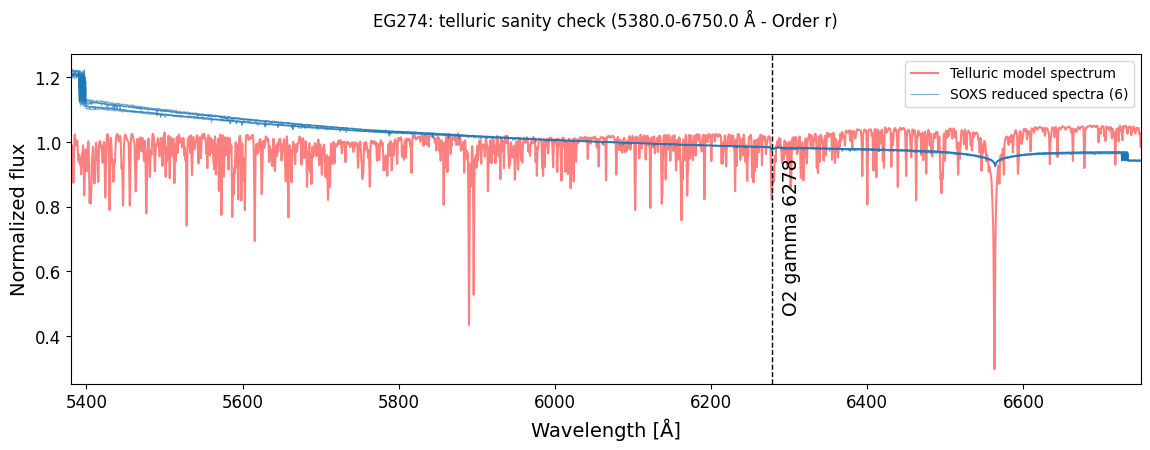

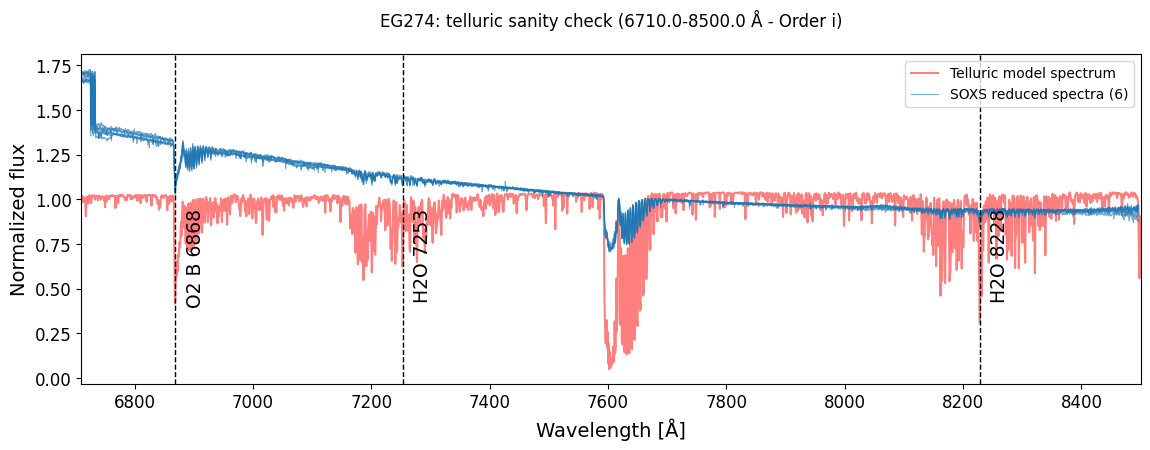

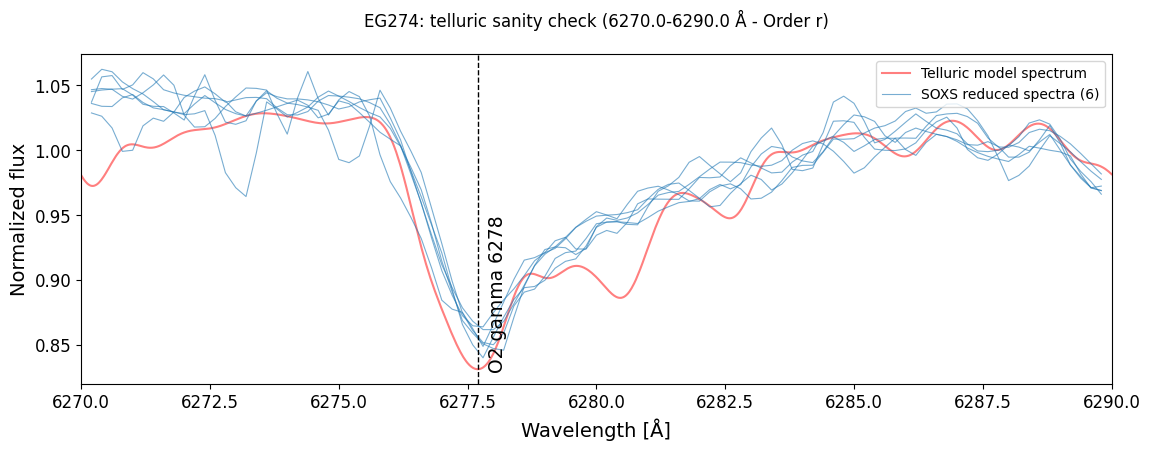

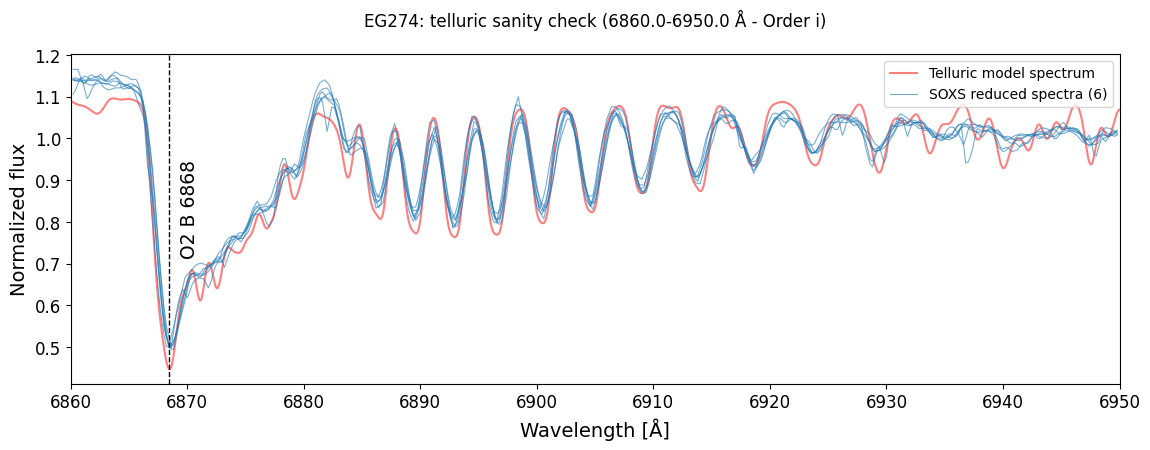

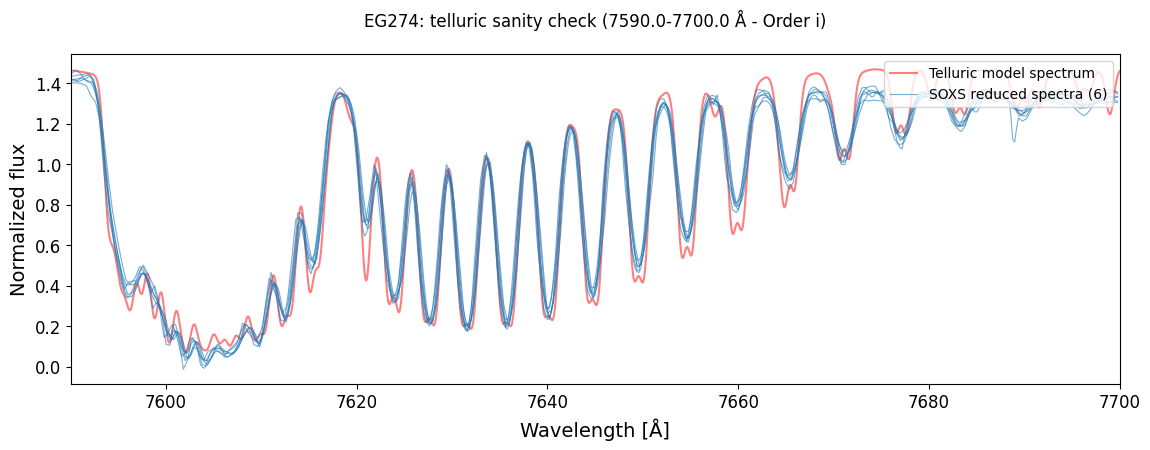

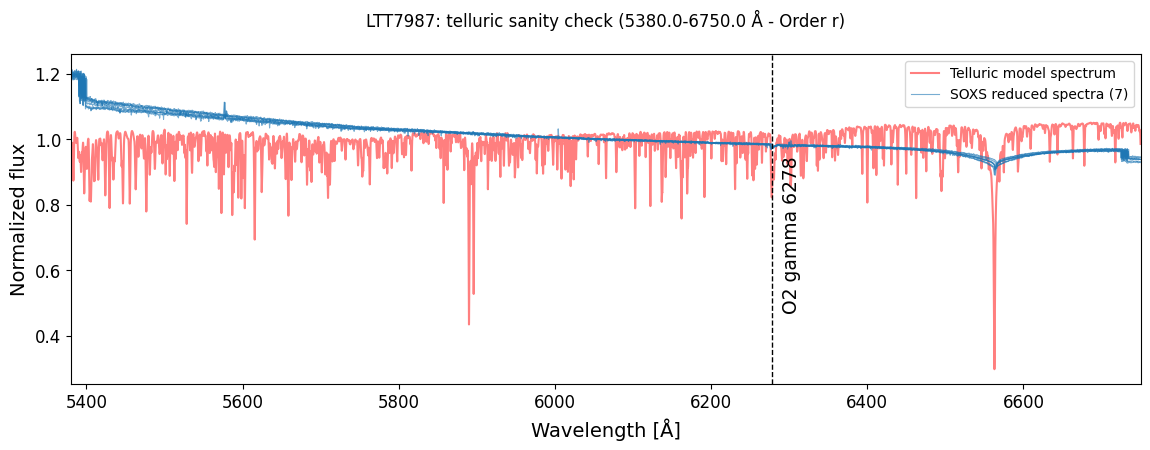

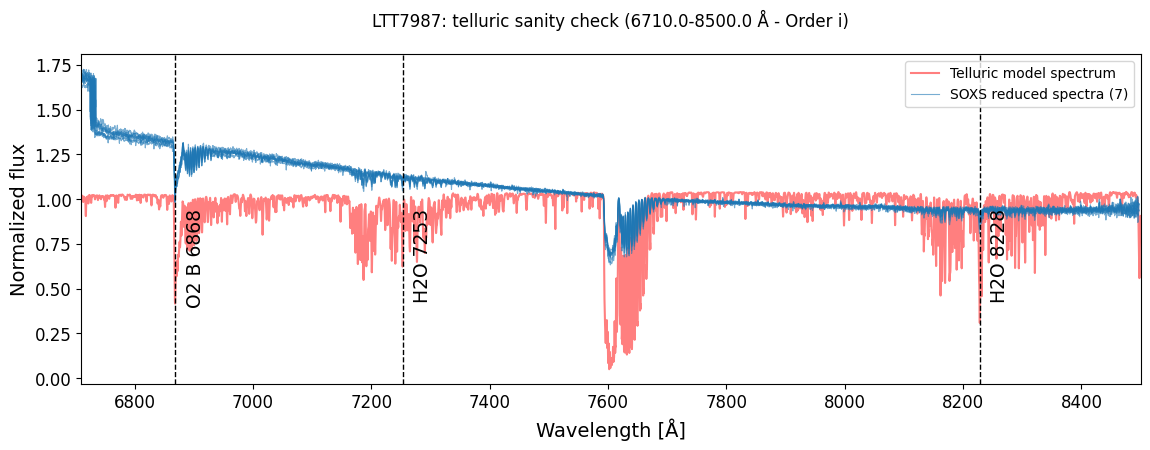

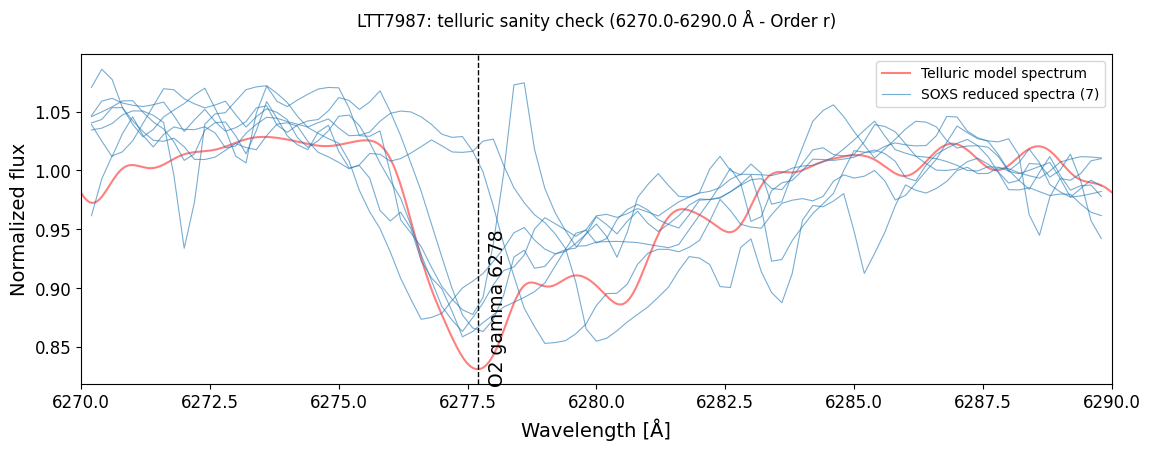

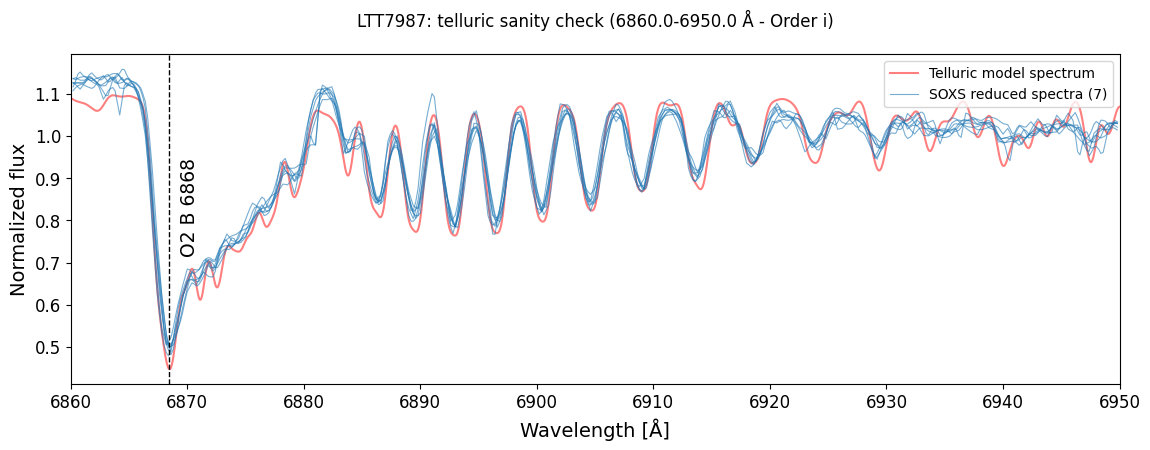

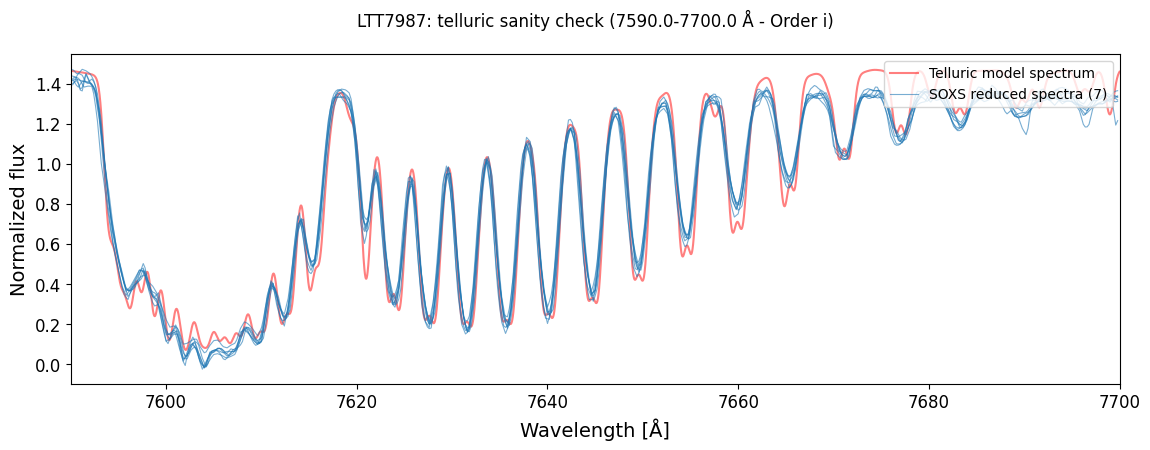

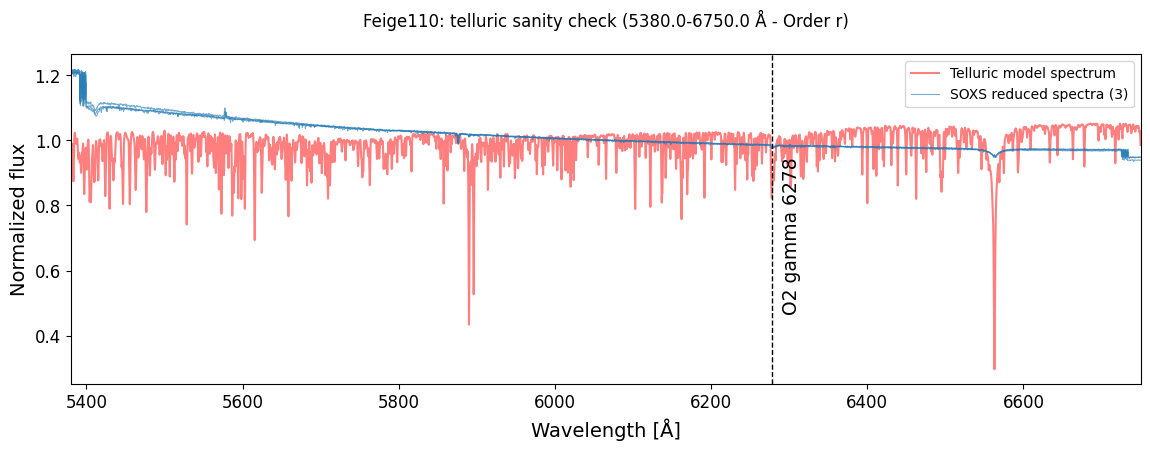

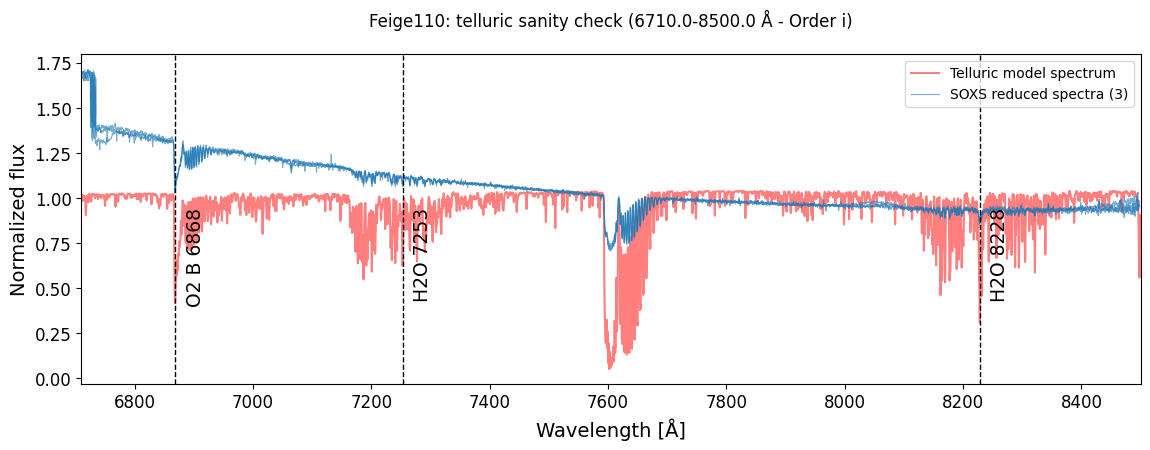

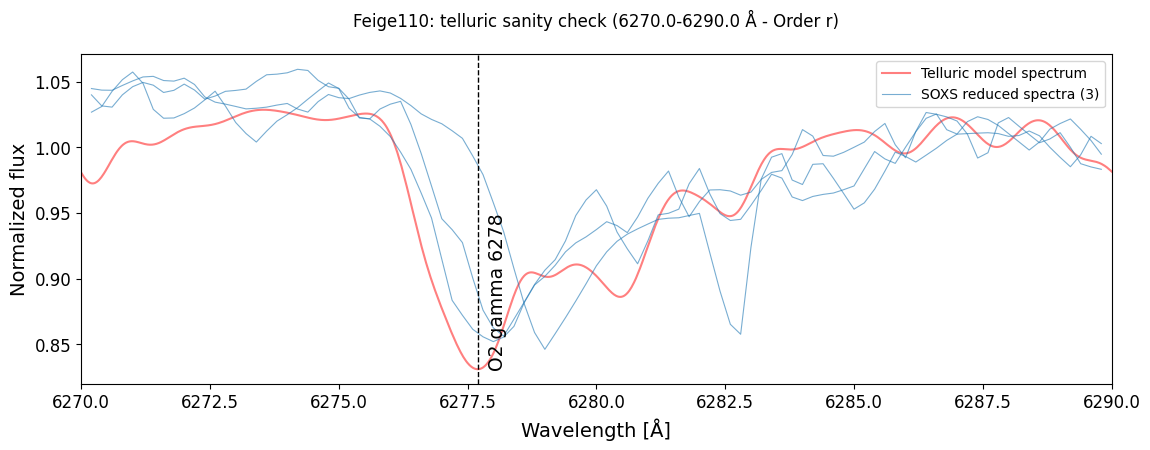

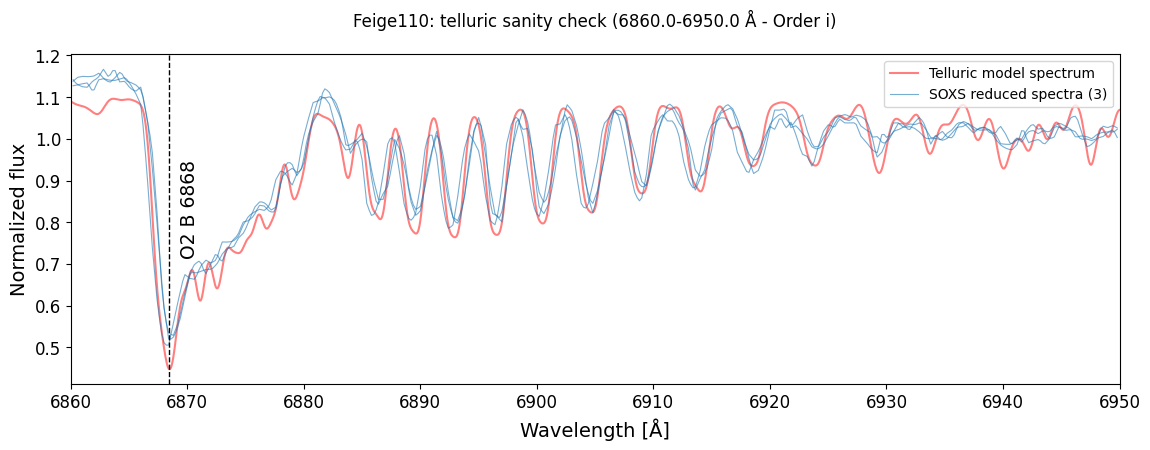

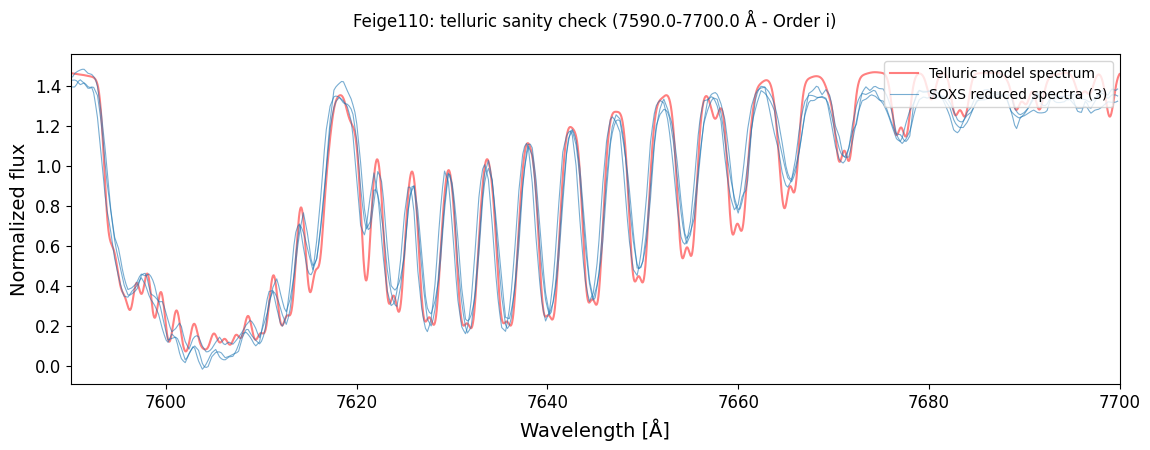

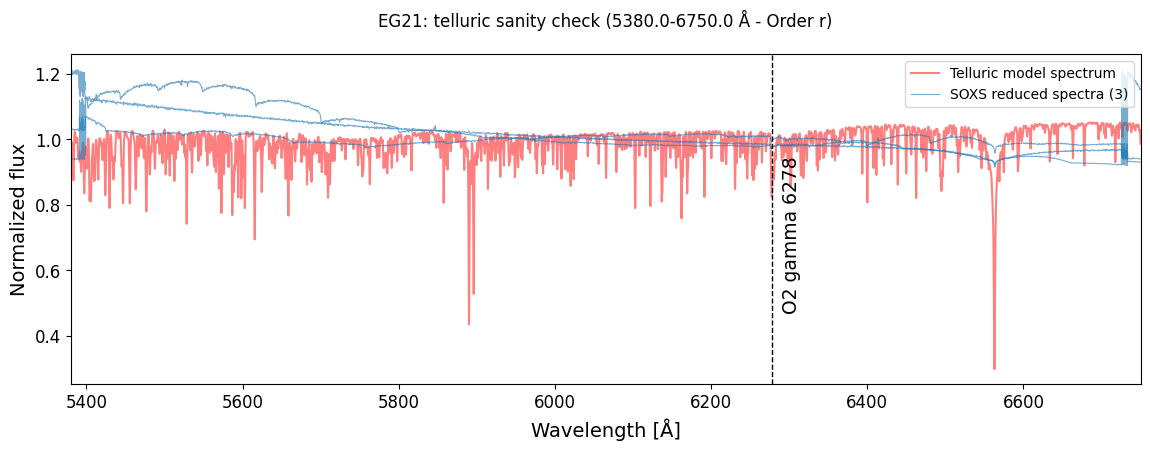

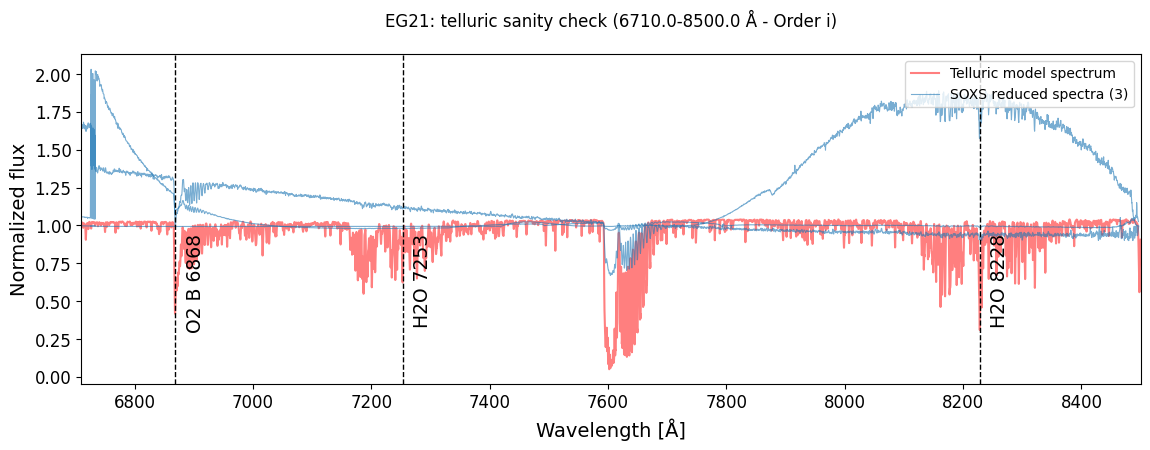

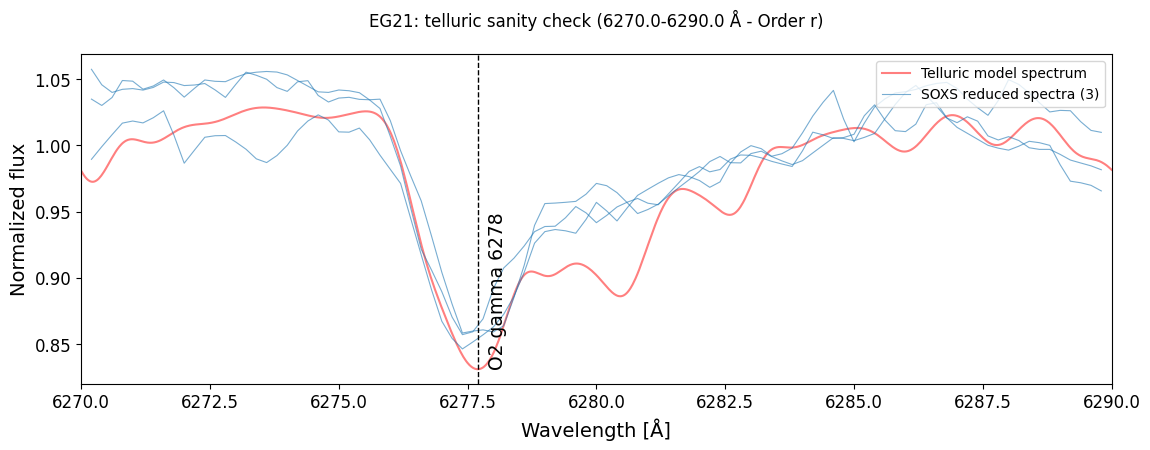

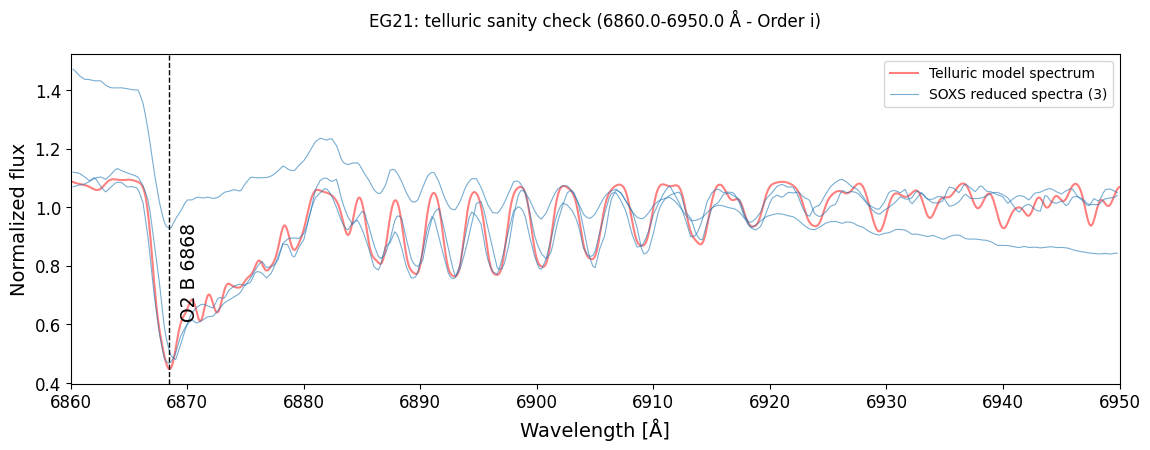

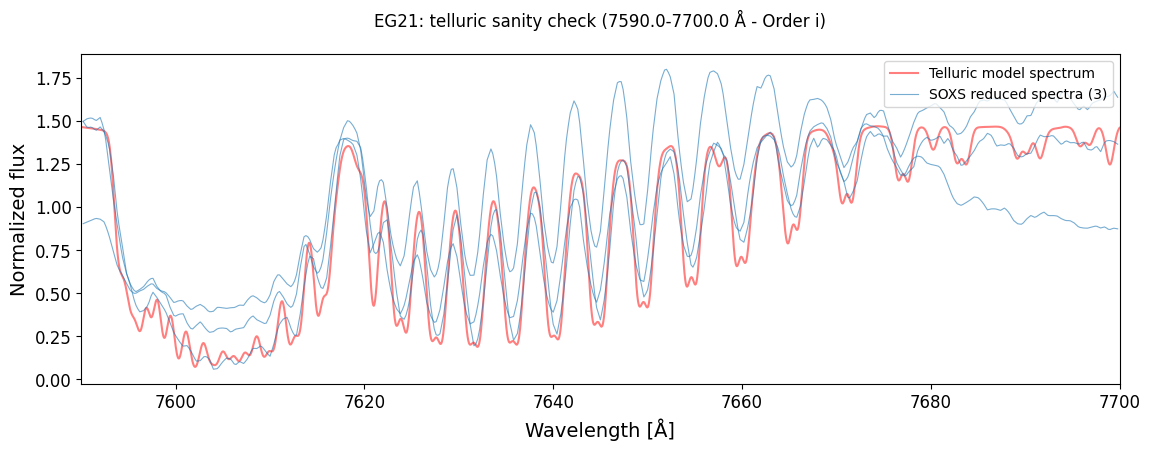

In [22]:
# DRIVER: TELLURIC SANITY-CHECK PLOTS FOR EVERY (STAR, TELLURIC WINDOW) COMBINATION
for starName in STANDARD_STARS:
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

    if len(matchedSpectra) == 0:
        continue

    for windowMin, windowMax in TELLURIC_WINDOWS:
        order = assign_spectral_order(windowMin, windowMax, spectralFormatDf)

        if ORDERS_TO_INSPECT is not None and order not in ORDERS_TO_INSPECT:
            continue

        plot_telluric_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            order,
            telluricSpectrumWaveAngstrom, telluricSpectrumFlux,
            savePath=f"{PLOTS_DIR}{starName}_{windowMin:.0f}-{windowMax:.0f}A_telluric.png",
        )
